# Van de Vusse NMPC - shrinking-horizon output surrogate and receding control

This notebook mirrors the control-surrogate workflow of notebook 04 for the smaller Van de Vusse CSTR benchmark. The true plant is the nonlinear isothermal reactor

```text
A -> B -> C,    2A -> D
```

with the dilution rate `D = F/V` as the manipulated input and `CB` as the desired product concentration.

## Problem definition

This notebook solves the **inverse-response operating-point transition problem** for the simplified four-concentration Van de Vusse model. The plant starts from the Set 1 inverse-response steady state, not from zero concentrations:

```text
x(0) = [CA, CB, CC, CD] = [3.0, 1.11702128, 3.25797872, 1.3125]
D_initial = 4/7 min^-1
```

The manipulated input is a piecewise-constant dilution-rate sequence `D_0, ..., D_99` with one move every `0.10 min = 6 s`, over a `10 min` horizon. The saved reference sequence was found by direct shooting on the true ODE to improve product concentration `CB` from this already-loaded reactor state, with a move penalty to discourage unnecessarily jumpy input changes.

Because the process has inverse response, a one-step maximization of `CB_{k+1}` can choose poor moves. The learning problem is therefore formulated as **shrinking-horizon output prediction**:

```text
[CA_k, CB_k, CC_k, CD_k, D_k, ..., D_{k+P-1}, horizon_frac]
    -> horizon_delta_CB_k = CB_{k+m} - CB_k,    m = min(P, H - k)
```

where `P` is the maximum prediction horizon and `m` is the number of active moves remaining to the fixed terminal step `H`, encoded as `horizon_frac = m / P` (unused control slots are held constant). The current concentrations are fixed measurements; the optimizer chooses only the future dilution-rate sequence. The receding controller maximizes predicted end-of-horizon `CB` minus a move penalty, applies only the first dilution-rate move to the true plant, then repeats from the new measured state. The horizon **shrinks** to the steps remaining as the run approaches `t = 10 min`, so near the end the surrogate predicts `CB` at the true terminal time rather than a constant `P` steps past it. Without this, a fixed `P`-step look-ahead has no terminal-time awareness and cannot reproduce the reference's end-loaded exit arc.

This simplified Van de Vusse benchmark has no pressure state or pressure constraint. Constraint handling here means respecting the dilution-rate bounds and checking the concentration state bounds. If a pressure variable is added later, it should be added as an additional prediction target and constraint output.

Scope for this benchmark:

- load the saved refined 6-second direct-shooting path from `datasets/vdv_refined_6sec_solution.npz`;
- build a shrinking-horizon `CB` training set (windows for every step `k = 0..H-1`, horizon `m = min(P, H - k)`) from the optimal trajectory plus local state/control-sequence perturbations;
- train tanh, ReLU, and PWL-tanh-compatible horizon-aware output surrogates;
- run receding closed-loop control by maximizing predicted end-of-horizon `CB` over bounded candidate dilution-rate sequences, shrinking the horizon near the terminal time;
- compare the closed-loop true-plant trajectories against the saved refined path.

No multiple-shooting benchmark is included here.


## Setup

In [1]:
from __future__ import annotations

from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "pyproject.toml").exists() and (candidate / "src" / "pwlnet").exists():
        ROOT = candidate
        break
if ROOT is None:
    raise RuntimeError("Could not find the PWLNet project root from the notebook working directory.")

src = ROOT / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from pwlnet import PWLNet
from pwlnet.formulations.pyomo_pwl import evaluate_tanh_pwl_network
from pwlnet.processes.van_de_vusse import (
    CONTROL_BOUNDS,
    DECISION_DT_MIN,
    OPERATING_POINT_1,
    OUTPUT_NAMES,
    STATE_BOUNDS,
    STATE_NAMES,
    VanDeVusseParameters,
    find_max_product_dilution,
    simulate_policy,
    solve_steady_state,
    step_state,
)

RANDOM_SEED = 2479085
rng = np.random.default_rng(RANDOM_SEED)
plt.style.use("seaborn-v0_8-whitegrid")

CB_IDX = OUTPUT_NAMES.index("CB")
D_LO, D_HI = CONTROL_BOUNDS[0]
N_STATE = len(STATE_NAMES)

# ``PREDICTION_HORIZON_STEPS`` is the *maximum* look-ahead P. The surrogate is made
# horizon-aware: it predicts the change in CB after only the first ``m`` of the P
# control slots, with ``m`` encoded by an extra normalized feature
# ``horizon_frac = m / P``. The receding controller then *shrinks* its horizon as it
# nears the fixed terminal time so it optimizes the true end-of-horizon CB instead of
# always looking a constant P steps past it.
PREDICTION_HORIZON_STEPS = 10
CONTROL_FEATURE_NAMES = [f"D_t+{j}" for j in range(PREDICTION_HORIZON_STEPS)]
HORIZON_FEATURE_NAME = "horizon_frac"
FEATURE_NAMES = [*STATE_NAMES, *CONTROL_FEATURE_NAMES, HORIZON_FEATURE_NAME]
CONTROL_SLICE = slice(N_STATE, N_STATE + PREDICTION_HORIZON_STEPS)
HORIZON_COL = N_STATE + PREDICTION_HORIZON_STEPS
TARGET_NAME = "horizon_delta_CB"
print(f"inputs: [{', '.join(FEATURE_NAMES)}], output: {TARGET_NAME}")


inputs: [CA, CB, CC, CD, D_t+0, D_t+1, D_t+2, D_t+3, D_t+4, D_t+5, D_t+6, D_t+7, D_t+8, D_t+9, horizon_frac], output: horizon_delta_CB


## Refined 6-second reference path

The reference path was computed by coarse-to-fine direct shooting on the true ODE and then refined on the default Van de Vusse control grid. The final profile is piecewise constant with `dt = 0.10 min = 6 s`, so it matches the default control problem. It is not a surrogate solution.

The concentration initial condition is the inverse-response Set 1 operating point, represented in this simplified model as the steady state at `D = 4/7 min^-1`. This makes the benchmark a transition/control problem from an already loaded reactor, not a zero-concentration startup.


In [2]:
OPT_PATH = ROOT / "datasets" / "vdv_refined_6sec_solution.npz"
if not OPT_PATH.exists():
    raise FileNotFoundError(
        f"Missing {OPT_PATH}. Run experiments/van_de_vusse/refine_default_control_sequence.py first."
    )

opt = np.load(OPT_PATH, allow_pickle=False)
D_star = opt["D"].astype(float)
opt_states = opt["states"].astype(float)
opt_times = opt["times"].astype(float)
DT = float(opt["dt_min"])
H = len(D_star)
x0 = opt_states[0].copy()
REFERENCE_LABEL = "refined 6-second inverse-response path"
INITIAL_CONDITION_LABEL = "Set 1 inverse-response steady state"
expected_x0 = solve_steady_state(OPERATING_POINT_1["D"]).x

if not np.isclose(DT, DECISION_DT_MIN):
    warnings.warn(
        f"Loaded reference uses dt={DT:g} min, while DECISION_DT_MIN={DECISION_DT_MIN:g} min."
    )
if not np.allclose(x0, expected_x0, atol=1e-8):
    warnings.warn(f"Expected Set 1 inverse-response initial state {expected_x0}, got {x0}.")

ss = find_max_product_dilution()
summary = pd.DataFrame([
    {
        "case": "steady-state CB optimum",
        "initial state": "steady state",
        "D": ss.dilution_rate,
        "dt [s]": np.nan,
        "moves": np.nan,
        "terminal CB": ss.cb,
        "integral CB": np.nan,
    },
    {
        "case": REFERENCE_LABEL,
        "initial state": INITIAL_CONDITION_LABEL,
        "D": np.nan,
        "dt [s]": 60.0 * DT,
        "moves": H,
        "terminal CB": opt_states[-1, CB_IDX],
        "integral CB": np.trapezoid(opt_states[:, CB_IDX], x=opt_times),
    },
])
display(summary.round(6))
pd.DataFrame({"time [min]": opt_times[:-1], "D*": D_star})


,case,initial state,D,dt [s],moves,terminal CB,integral CB
0,steady-state CB optimum,steady state,1.292092,NaN,NaN,1.265986,NaN
1,refined 6-second inverse-response path,Set 1 inverse-response steady state,NaN,6.0,100.0,1.614158,12.377319


,time [min],D*
0,0.0,1.654673
1,0.1,1.787976
2,0.2,1.865734
3,0.3,1.888021
4,0.4,1.819536
...,...,...
95,9.5,0.463193
96,9.6,0.100000
97,9.7,0.100000
98,9.8,0.100000


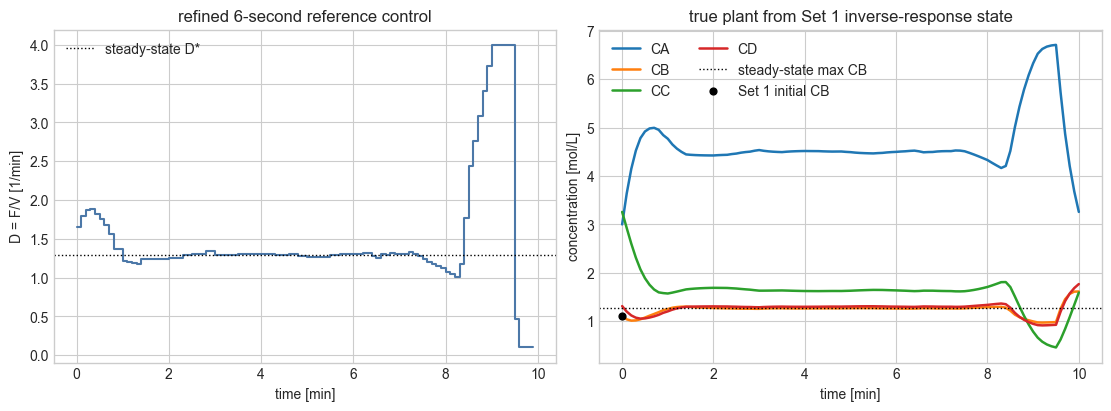

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax[0].step(opt_times[:-1], D_star, where="post", color="#4c78a8")
ax[0].axhline(ss.dilution_rate, color="black", ls=":", lw=1, label="steady-state D*")
ax[0].set(xlabel="time [min]", ylabel="D = F/V [1/min]", title="refined 6-second reference control")
ax[0].legend(frameon=False)

for i, name in enumerate(OUTPUT_NAMES):
    ax[1].plot(opt_times, opt_states[:, i], lw=1.8, label=name)
ax[1].axhline(ss.cb, color="black", ls=":", lw=1, label="steady-state max CB")
ax[1].scatter([opt_times[0]], [opt_states[0, CB_IDX]], color="black", s=24, zorder=4, label="Set 1 initial CB")
ax[1].set(xlabel="time [min]", ylabel="concentration [mol/L]", title="true plant from Set 1 inverse-response state")
ax[1].legend(frameon=False, ncol=2)
plt.show()


## Shrinking-horizon `CB` dataset around the refined path

The base samples are windows on the refined trajectory. Each row fixes the current concentrations, appends up to `P` dilution-rate moves plus the `horizon_frac` feature, and targets the change in the desired compound over the active horizon, `CB_{k+m} - CB_k`. Crucially the window loop now runs to `k = H - 1` with `m = min(P, H - k)`, so the **terminal exit arc is covered for every step** -- the previous fixed-horizon dataset stopped at `k = H - P`, leaving the last `P - 1` steps (and the end-of-horizon `CB` spike) essentially unseen, which is why the old controller could not reproduce the terminal move. The notebook then builds a local cloud around each window by perturbing the initial concentrations and the candidate control sequence, clipping to feasible bounds, and simulating the true plant over the active horizon; a few extra random-horizon samples per window exercise `horizon_frac` across the whole trajectory.


In [4]:
def pad_control_window(profile, start, horizon_steps):
    window = np.asarray(profile[start:start + horizon_steps], dtype=float)
    if len(window) < horizon_steps:
        fill = window[-1] if len(window) else profile[-1]
        window = np.r_[window, np.full(horizon_steps - len(window), fill)]
    return window


def hold_to_length(active_moves, length):
    """Zero-order-hold an active control sub-sequence up to ``length`` slots.

    Beyond the active moves the last value is repeated so the unused tail is a benign
    constant (the same convention used at training and control time), which the
    ``horizon_frac`` feature tells the network to ignore.
    """
    active = np.asarray(active_moves, dtype=float)
    if len(active) >= length:
        return active[:length].copy()
    fill = active[-1] if len(active) else 0.0
    return np.r_[active, np.full(length - len(active), fill)]


def simulate_horizon_delta_cb(state, active_moves):
    """Apply only the ``len(active_moves)`` active moves and return ``CB_end - CB_now``."""
    x = np.asarray(state, dtype=float).copy()
    for d in np.asarray(active_moves, dtype=float):
        x = step_state(x, float(d), dt_min=DT, n_substeps=12)
    return float(x[CB_IDX] - state[CB_IDX]), x


def make_terminal_cb_dataset(
    n_local_per_window=18,
    n_horizon_aug=6,
    state_scales=(0.12, 0.06, 0.16, 0.14),
    control_scale=0.18,
    control_walk_scale=0.08,
):
    rows_x, rows_y, rows_meta = [], [], []
    state_scales = np.asarray(state_scales, dtype=float)

    for k in range(H):
        # Steps remaining from k to the fixed terminal time, capped at the maximum P.
        m_full = min(PREDICTION_HORIZON_STEPS, H - k)
        x_ref = np.asarray(opt_states[k], dtype=float)

        # Unperturbed reference window at the full remaining horizon. Because the loop
        # now runs to k = H - 1 (not H - P), the terminal exit arc -- including the
        # end-of-horizon CB spike -- is represented for every step instead of only the
        # single k = H - P window that the previous fixed-horizon dataset contained.
        d_ref_active = D_star[k:k + m_full]
        terminal_delta_ref = float(opt_states[k + m_full, CB_IDX] - opt_states[k, CB_IDX])
        rows_x.append(np.r_[x_ref, hold_to_length(d_ref_active, PREDICTION_HORIZON_STEPS), m_full / PREDICTION_HORIZON_STEPS])
        rows_y.append([terminal_delta_ref])
        rows_meta.append({"source": "reference", "time": opt_times[k], "step": k, "horizon": m_full})

        # Local cloud: n_local_per_window samples at the horizon the controller will
        # actually use at step k, plus n_horizon_aug samples at random shorter horizons
        # so ``horizon_frac`` is exercised densely across the whole trajectory.
        horizons = [m_full] * n_local_per_window
        horizons += [int(rng.integers(1, m_full + 1)) for _ in range(n_horizon_aug)]
        for m in horizons:
            x0_local = x_ref + rng.normal(0.0, state_scales)
            x0_local = np.clip(x0_local, STATE_BOUNDS[:, 0], STATE_BOUNDS[:, 1])
            d_noise = rng.normal(0.0, control_scale, size=m)
            d_noise += np.cumsum(rng.normal(0.0, control_walk_scale, size=m))
            d_active = np.clip(D_star[k:k + m] + d_noise, D_LO, D_HI)
            terminal_delta_cb, _ = simulate_horizon_delta_cb(x0_local, d_active)
            rows_x.append(np.r_[x0_local, hold_to_length(d_active, PREDICTION_HORIZON_STEPS), m / PREDICTION_HORIZON_STEPS])
            rows_y.append([terminal_delta_cb])
            rows_meta.append({"source": "local perturbation", "time": opt_times[k], "step": k, "horizon": m})

    X = np.asarray(rows_x, dtype=float)
    Y = np.asarray(rows_y, dtype=float)
    meta = pd.DataFrame(rows_meta)
    return X, Y, meta


t0 = time.perf_counter()
X, Y, sample_meta = make_terminal_cb_dataset()
gen_seconds = time.perf_counter() - t0

perm = rng.permutation(len(X))
n_train = int(0.70 * len(perm))
n_val = int(0.15 * len(perm))
train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]

X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
X_test, Y_test = X[test_idx], Y[test_idx]

print(
    f"generated {len(X)} horizon-CB samples from {H} shrinking-horizon windows "
    f"(k = 0..{H - 1}) in {gen_seconds:.2f}s"
)
print(
    f"max prediction horizon P = {PREDICTION_HORIZON_STEPS} steps = "
    f"{PREDICTION_HORIZON_STEPS * DT:.2f} min; terminal windows shrink down to 1 step"
)
print(f"train={X_train.shape}, validation={X_val.shape}, test={X_test.shape}")
summary = pd.DataFrame(X, columns=FEATURE_NAMES).describe().T
summary.loc[TARGET_NAME, :] = np.nan
summary.loc[TARGET_NAME, ["mean", "std", "min", "max"]] = [Y.mean(), Y.std(), Y.min(), Y.max()]
display(summary.round(6))


generated 2500 horizon-CB samples from 100 shrinking-horizon windows (k = 0..99) in 6.58s
max prediction horizon P = 10 steps = 1.00 min; terminal windows shrink down to 1 step
train=(1750, 15), validation=(375, 15), test=(375, 15)


,count,mean,std,min,25%,50%,75%,max
CA,2500.0,4.650833,0.613546,2.802952,4.397526,4.508665,4.650126,6.985393
CB,2500.0,1.235804,0.123022,0.849960,1.188662,1.257930,1.302163,1.704860
CC,2500.0,1.588554,0.423879,0.141071,1.480558,1.623690,1.750607,3.718837
CD,2500.0,1.258738,0.187620,0.528527,1.150961,1.281970,1.378457,1.937654
D_t+0,2500.0,1.484847,0.769798,0.100000,1.157697,1.309324,1.521137,4.000000
D_t+1,2500.0,1.474358,0.777744,0.100000,1.139496,1.322714,1.540424,4.000000
D_t+2,2500.0,1.457503,0.791908,0.100000,1.124489,1.310170,1.531926,4.000000
D_t+3,2500.0,1.445945,0.803449,0.100000,1.094811,1.302812,1.549374,4.000000
D_t+4,2500.0,1.430833,0.819188,0.100000,1.072930,1.294154,1.544827,4.000000
D_t+5,2500.0,1.419411,0.826995,0.100000,1.060991,1.297424,1.549624,4.000000


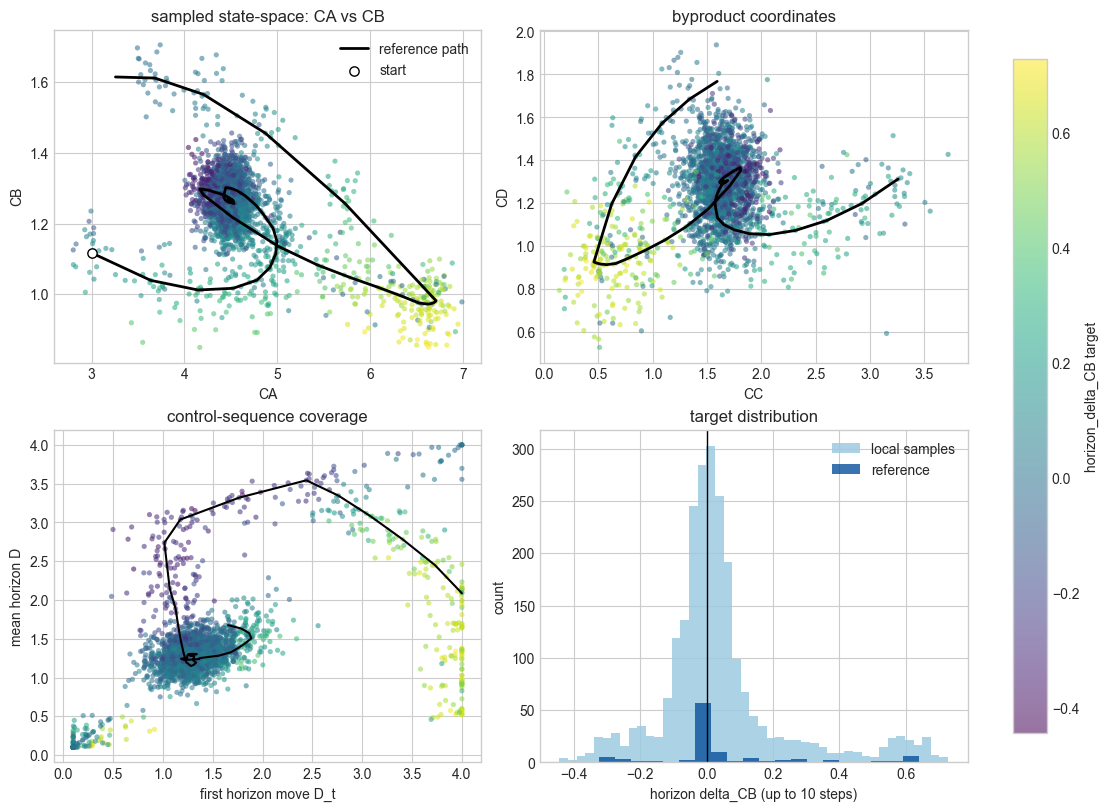

In [5]:
plot_df = pd.DataFrame(X[:, :N_STATE], columns=STATE_NAMES)
plot_df["D_first"] = X[:, N_STATE]
plot_df["D_mean"] = X[:, CONTROL_SLICE].mean(axis=1)
plot_df[TARGET_NAME] = Y[:, 0]
plot_df["source"] = sample_meta["source"].to_numpy()

fig, ax = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
scatter_kwargs = dict(c=plot_df[TARGET_NAME], cmap="viridis", s=14, alpha=0.55, linewidths=0)

sc = ax[0, 0].scatter(plot_df["CA"], plot_df["CB"], **scatter_kwargs)
ax[0, 0].plot(opt_states[:, 0], opt_states[:, 1], color="black", lw=2, label="reference path")
ax[0, 0].scatter(opt_states[0, 0], opt_states[0, 1], color="white", edgecolor="black", s=45, zorder=3, label="start")
ax[0, 0].set(xlabel="CA", ylabel="CB", title="sampled state-space: CA vs CB")
ax[0, 0].legend(frameon=False)

ax[0, 1].scatter(plot_df["CC"], plot_df["CD"], **scatter_kwargs)
ax[0, 1].plot(opt_states[:, 2], opt_states[:, 3], color="black", lw=2)
ax[0, 1].set(xlabel="CC", ylabel="CD", title="byproduct coordinates")

ax[1, 0].scatter(plot_df["D_first"], plot_df["D_mean"], **scatter_kwargs)
ax[1, 0].plot(D_star[:-PREDICTION_HORIZON_STEPS + 1], [
    pad_control_window(D_star, k, PREDICTION_HORIZON_STEPS).mean()
    for k in range(H - PREDICTION_HORIZON_STEPS + 1)
], color="black", lw=1.5)
ax[1, 0].set(xlabel="first horizon move D_t", ylabel="mean horizon D", title="control-sequence coverage")

is_ref = plot_df["source"].eq("reference")
ax[1, 1].hist(plot_df.loc[~is_ref, TARGET_NAME], bins=45, color="#9ecae1", alpha=0.85, label="local samples")
ax[1, 1].hist(plot_df.loc[is_ref, TARGET_NAME], bins=20, color="#08519c", alpha=0.80, label="reference")
ax[1, 1].axvline(0.0, color="black", lw=1)
ax[1, 1].set(xlabel=f"horizon delta_CB (up to {PREDICTION_HORIZON_STEPS} steps)", ylabel="count", title="target distribution")
ax[1, 1].legend(frameon=False)

cbar = fig.colorbar(sc, ax=ax[:, :], shrink=0.92)
cbar.set_label("horizon_delta_CB target")
plt.show()


## Train horizon-aware output surrogates

The networks learn the change in the desired compound over a *variable* prediction horizon: the input carries the `P` dilution-rate slots plus a normalized `horizon_frac = m / P` feature, and the target is `CB_{k+m} - CB_k` for the first `m` active moves (the unused tail slots are held constant). During receding control the predicted product concentration is reconstructed as `CB_k + horizon_delta_CB_hat`, where `m` shrinks to the steps remaining as `t -> 10 min`. The PWL-tanh version is still evaluated from the same tanh network with a piecewise-linear activation approximation.


In [6]:
COMMON_TRAIN = dict(
    epochs=450,
    batch_size=96,
    validation_split=0.0,
    verbose=0,
    random_seed=RANDOM_SEED,
)

MODEL_SPECS = {
    "tanh Smooth": dict(hidden_layers=[24, 16], activation="tanh"),
    "ReLU": dict(hidden_layers=[24, 16], activation="relu"),
}

t0 = time.perf_counter()
tanh_net = PWLNet.train(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    **MODEL_SPECS["tanh Smooth"],
    **COMMON_TRAIN,
)
tanh_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
relu_net = PWLNet.train(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    **MODEL_SPECS["ReLU"],
    **COMMON_TRAIN,
)
relu_seconds = time.perf_counter() - t0

print(f"tanh training: {tanh_seconds:.2f}s")
print(f"ReLU training: {relu_seconds:.2f}s")


tanh training: 53.51s
ReLU training: 47.57s


## Terminal-horizon `CB` prediction accuracy


In [7]:
BP = 5
predictions = {
    "tanh Smooth": tanh_net.predict(X_test),
    "ReLU": relu_net.predict(X_test),
    "tanh PWL-5": evaluate_tanh_pwl_network(tanh_net.network, X_test, breakpoints=BP),
}

rows = []
y_true = Y_test[:, 0]
for label, pred in predictions.items():
    y_pred = np.asarray(pred, dtype=float).reshape(-1)
    err = y_pred - y_true
    denom = np.sum((y_true - y_true.mean()) ** 2)
    rows.append({
        "model": label,
        "target": TARGET_NAME,
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "max abs error": np.max(np.abs(err)),
        "R2": 1.0 - np.sum(err ** 2) / denom if denom > 0 else np.nan,
    })
metrics = pd.DataFrame(rows)
display(metrics.round(6))


,model,target,MAE,RMSE,max abs error,R2
0,tanh Smooth,horizon_delta_CB,0.006361,0.010113,0.060517,0.997759
1,ReLU,horizon_delta_CB,0.007381,0.012415,0.079526,0.996623
2,tanh PWL-5,horizon_delta_CB,0.043639,0.050987,0.156446,0.943037


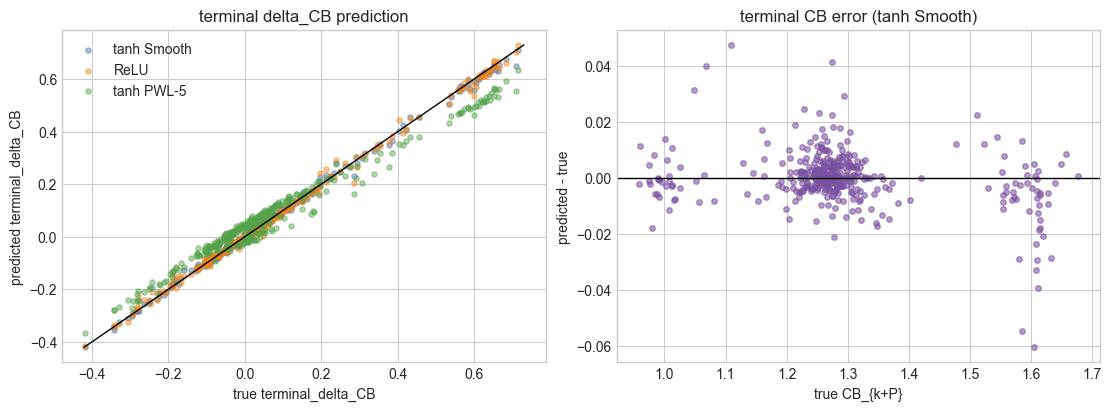

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
colors = {"tanh Smooth": "#4c78a8", "ReLU": "#f58518", "tanh PWL-5": "#54a24b"}

for label, pred in predictions.items():
    y_pred = np.asarray(pred, dtype=float).reshape(-1)
    ax[0].scatter(y_true, y_pred, s=14, alpha=0.45, label=label, color=colors.get(label))
lo = min(y_true.min(), *(np.asarray(p).reshape(-1).min() for p in predictions.values()))
hi = max(y_true.max(), *(np.asarray(p).reshape(-1).max() for p in predictions.values()))
ax[0].plot([lo, hi], [lo, hi], color="black", lw=1)
ax[0].set(title="terminal delta_CB prediction", xlabel="true terminal_delta_CB", ylabel="predicted terminal_delta_CB")
ax[0].legend(frameon=False)

best_label = metrics.sort_values("RMSE").iloc[0]["model"]
best_pred = np.asarray(predictions[best_label], dtype=float).reshape(-1)
terminal_cb_true = X_test[:, CB_IDX] + y_true
terminal_cb_pred = X_test[:, CB_IDX] + best_pred
err = terminal_cb_pred - terminal_cb_true
ax[1].scatter(terminal_cb_true, err, s=16, alpha=0.55, color="#7b4fa1")
ax[1].axhline(0.0, color="black", lw=1)
ax[1].set(title=f"terminal CB error ({best_label})", xlabel="true CB_{k+P}", ylabel="predicted - true")
plt.show()


## Receding shrinking-horizon control

At each 6-second move, the current measured concentration state is fixed as an equality constraint and the controller optimizes only a candidate sequence of future dilution rates. The score is predicted end-of-horizon `CB` minus a move penalty; only the first move is applied to the true plant before the problem is rebuilt at the next measured state.

The horizon now **shrinks** as the run approaches the fixed terminal time `t = 10 min`. At step `k` the controller uses `m = min(P, H - k)` active moves and sets `horizon_frac = m / P`, so for the last `P` steps the surrogate predicts `CB` at the *true* terminal step instead of a constant `P` steps beyond it. This is the fix for the previous failure mode: with a fixed `P`-step look-ahead the controller never "saw the clock running out", so near the end it kept `D` pinned high and skipped the optimal terminal exit arc -- the brief `D -> D_min` crash that lets accumulated reactant convert into the end-of-horizon `CB` spike. With the shrinking horizon, and with the training set now covering those terminal windows, the controller commits to the exit arc and recovers a terminal `CB` close to the refined reference.

The reformulation still handles inverse response: a move can be accepted even if it hurts the immediate next `CB`, as long as it improves the (now correctly-timed) end-of-horizon prediction.


In [9]:
def predict_terminal_delta_cb(label, X_eval):
    if label == "tanh Smooth":
        return tanh_net.predict(X_eval).reshape(-1)
    if label == "ReLU":
        return relu_net.predict(X_eval).reshape(-1)
    if label == "tanh PWL-5":
        return evaluate_tanh_pwl_network(tanh_net.network, X_eval, breakpoints=BP).reshape(-1)
    raise KeyError(label)


def max_state_bound_violation(states):
    states = np.asarray(states, dtype=float)
    low = np.maximum(STATE_BOUNDS[:, 0] - states, 0.0)
    high = np.maximum(states - STATE_BOUNDS[:, 1], 0.0)
    return float(np.max(np.maximum(low, high)))


def fixed_state_sequence_rows(current_state, control_sequences, horizon_frac):
    """Build surrogate inputs: fixed measured state, varying D sequence, horizon feature."""
    current_state = np.asarray(current_state, dtype=float).reshape(N_STATE)
    control_sequences = np.asarray(control_sequences, dtype=float)
    candidate_rows = np.column_stack([
        np.repeat(current_state[None, :], len(control_sequences), axis=0),
        control_sequences,
        np.full((len(control_sequences), 1), float(horizon_frac)),
    ])
    fixed_state_error = float(np.max(np.abs(candidate_rows[:, :N_STATE] - current_state)))
    if fixed_state_error > 1e-12:
        raise RuntimeError("Terminal-horizon candidate rows changed the measured state columns.")
    return candidate_rows, fixed_state_error


def candidate_control_sequences(step_index, d_prev, horizon, candidate_count=800):
    """Candidates for the ``horizon`` active moves, zero-order-held to the P input slots."""
    m = int(horizon)
    start = min(step_index, H - 1)
    ref_active = hold_to_length(D_star[start:start + m], m)
    sequences = [
        hold_to_length(ref_active, PREDICTION_HORIZON_STEPS),
        hold_to_length(np.full(m, d_prev), PREDICTION_HORIZON_STEPS),
        hold_to_length(np.linspace(d_prev, ref_active[-1], m), PREDICTION_HORIZON_STEPS),
    ]
    random_count = max(0, int(candidate_count) - len(sequences))
    for _ in range(random_count):
        noise = rng.normal(0.0, 0.24, size=m)
        noise += np.cumsum(rng.normal(0.0, 0.08, size=m))
        seq = np.clip(ref_active + noise, D_LO, D_HI)
        seq[0] = np.clip(0.70 * seq[0] + 0.30 * d_prev, D_LO, D_HI)
        sequences.append(hold_to_length(seq, PREDICTION_HORIZON_STEPS))
    return np.asarray(sequences, dtype=float)


def run_terminal_horizon_control(label, *, move_penalty=0.001, candidate_count=800):
    states = [x0.copy()]
    controls = []
    predicted_terminal_cb = []
    scores = []
    horizons = []
    fixed_state_errors = []
    d_prev = float(OPERATING_POINT_1["D"])

    for k in range(H):
        x_curr = states[-1]
        # Shrinking horizon: never look past the fixed terminal time t = H * dt. For the
        # last P steps m = H - k < P, so the surrogate predicts CB at the *true* terminal
        # step rather than P steps beyond it -- this is what lets the controller commit to
        # the end-of-horizon exit arc instead of holding D high through the finish.
        m = min(PREDICTION_HORIZON_STEPS, H - k)
        horizon_frac = m / PREDICTION_HORIZON_STEPS
        control_sequences = candidate_control_sequences(k, d_prev, m, candidate_count=candidate_count)
        X_eval, fixed_state_error = fixed_state_sequence_rows(x_curr, control_sequences, horizon_frac)
        terminal_delta_cb = predict_terminal_delta_cb(label, X_eval)
        terminal_cb = x_curr[CB_IDX] + terminal_delta_cb
        active = control_sequences[:, :m]
        diffs = np.diff(np.column_stack([np.full(len(active), d_prev), active]), axis=1)
        move_cost = np.sum(np.abs(diffs), axis=1)
        score = terminal_cb - float(move_penalty) * move_cost
        best = int(np.argmax(score))
        d = float(control_sequences[best, 0])
        x_next = step_state(x_curr, d, dt_min=DT, n_substeps=12)
        states.append(x_next)
        controls.append(d)
        predicted_terminal_cb.append(float(terminal_cb[best]))
        scores.append(float(score[best]))
        horizons.append(int(m))
        fixed_state_errors.append(fixed_state_error)
        d_prev = d

    states = np.asarray(states)
    controls = np.asarray(controls)
    times = np.arange(len(states)) * DT
    control_times = times[:-1]
    return {
        "status": "ok",
        "times": times,
        "control_times": control_times,
        "states": states,
        "controls": controls,
        "predicted_terminal_CB": np.asarray(predicted_terminal_cb),
        "scores": np.asarray(scores),
        "horizons": np.asarray(horizons),
        "prediction_horizon_steps": PREDICTION_HORIZON_STEPS,
        "move_penalty": float(move_penalty),
        "fixed_state_error": float(np.max(fixed_state_errors)),
        "state_bound_violation": max_state_bound_violation(states),
    }


RECEDING_MODELS = ["tanh Smooth", "ReLU", "tanh PWL-5"]
t0 = time.perf_counter()
receding_runs = {
    label: run_terminal_horizon_control(label, move_penalty=0.001)
    for label in RECEDING_MODELS
}
receding_seconds = time.perf_counter() - t0
print(f"ran {len(receding_runs)} shrinking-horizon controllers in {receding_seconds:.2f}s")
receding_runs


ran 3 shrinking-horizon controllers in 4.01s


{'tanh Smooth': {'status': 'ok',
  'times': array([ 0. ,  0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,
          1.1,  1.2,  1.3,  1.4,  1.5,  1.6,  1.7,  1.8,  1.9,  2. ,  2.1,
          2.2,  2.3,  2.4,  2.5,  2.6,  2.7,  2.8,  2.9,  3. ,  3.1,  3.2,
          3.3,  3.4,  3.5,  3.6,  3.7,  3.8,  3.9,  4. ,  4.1,  4.2,  4.3,
          4.4,  4.5,  4.6,  4.7,  4.8,  4.9,  5. ,  5.1,  5.2,  5.3,  5.4,
          5.5,  5.6,  5.7,  5.8,  5.9,  6. ,  6.1,  6.2,  6.3,  6.4,  6.5,
          6.6,  6.7,  6.8,  6.9,  7. ,  7.1,  7.2,  7.3,  7.4,  7.5,  7.6,
          7.7,  7.8,  7.9,  8. ,  8.1,  8.2,  8.3,  8.4,  8.5,  8.6,  8.7,
          8.8,  8.9,  9. ,  9.1,  9.2,  9.3,  9.4,  9.5,  9.6,  9.7,  9.8,
          9.9, 10. ]),
  'control_times': array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
         1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. , 2.1, 2.2, 2.3, 2.4, 2.5,
         2.6, 2.7, 2.8, 2.9, 3. , 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8,
         3.9, 4. , 4.

In [10]:
rows = []
for label, run in receding_runs.items():
    states = run["states"]
    controls = run["controls"]
    rows.append({
        "controller": label,
        "status": run["status"],
        "terminal CB": states[-1, CB_IDX],
        "integral CB": np.trapezoid(states[:, CB_IDX], x=run["times"]),
        "D min": np.min(controls),
        "D max": np.max(controls),
        "max |delta D|": np.max(np.abs(np.diff(np.r_[OPERATING_POINT_1["D"], controls]))),
        "prediction horizon [steps]": run["prediction_horizon_steps"],
        "max fixed-state error": run["fixed_state_error"],
        "state bound violation": run["state_bound_violation"],
    })
rows.append({
    "controller": "refined direct-shooting reference",
    "status": "reference",
    "terminal CB": opt_states[-1, CB_IDX],
    "integral CB": np.trapezoid(opt_states[:, CB_IDX], x=opt_times),
    "D min": float(np.min(D_star)),
    "D max": float(np.max(D_star)),
    "max |delta D|": float(np.max(np.abs(np.diff(np.r_[OPERATING_POINT_1["D"], D_star])))),
    "prediction horizon [steps]": PREDICTION_HORIZON_STEPS,
    "max fixed-state error": 0.0,
    "state bound violation": max_state_bound_violation(opt_states),
})
results_table = pd.DataFrame(rows)
display(results_table.round(6))


,controller,status,terminal CB,integral CB,D min,D max,max |delta D|,prediction horizon [steps],max fixed-state error,state bound violation
0,tanh Smooth,ok,1.609610,12.404966,0.1,3.963601,2.704521,10,0.0,0.0
1,ReLU,ok,1.601668,12.392101,0.1,3.948669,2.195847,10,0.0,0.0
2,tanh PWL-5,ok,1.609927,12.390740,0.1,3.988596,2.519226,10,0.0,0.0
3,refined direct-shooting reference,reference,1.614158,12.377319,0.1,4.000000,3.536807,10,0.0,0.0


saved C:\Users\Sunoy\University\PY_M_projects\PWLNet\images\article\vdv_closed_loop.pdf (+ .png)


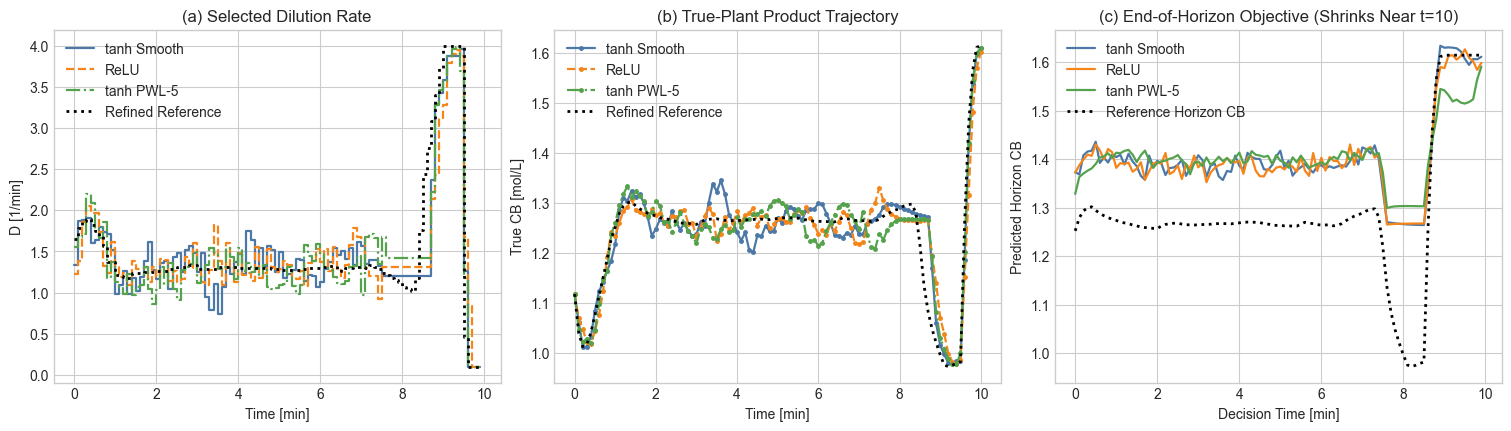

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
colors = {"tanh Smooth": "#4c78a8", "ReLU": "#f58518", "tanh PWL-5": "#54a24b"}
styles = {"tanh Smooth": "-", "ReLU": "--", "tanh PWL-5": "-."}
for label, run in receding_runs.items():
    ax[0].step(run["control_times"], run["controls"], where="post", label=label, color=colors.get(label), linestyle=styles.get(label), lw=1.6)
    ax[1].plot(run["times"], run["states"][:, CB_IDX], marker="o", ms=2.5, label=label, color=colors.get(label), linestyle=styles.get(label), lw=1.6)
    ax[2].plot(run["control_times"], run["predicted_terminal_CB"], lw=1.6, label=label, color=colors.get(label))

# Reference end-of-horizon target, shrinking to the fixed terminal time over the last P steps.
ref_horizon_cb = np.array([opt_states[min(k + PREDICTION_HORIZON_STEPS, H), CB_IDX] for k in range(H)])
ax[0].step(opt_times[:-1], D_star, where="post", color="black", ls=":", lw=2, label="Refined Reference")
ax[1].plot(opt_times, opt_states[:, CB_IDX], color="black", ls=":", lw=2, label="Refined Reference")
ax[2].plot(opt_times[:-1], ref_horizon_cb, color="black", ls=":", lw=2, label="Reference Horizon CB")
ax[0].set(xlabel="Time [min]", ylabel="D [1/min]", title="(a) Selected Dilution Rate")
ax[1].set(xlabel="Time [min]", ylabel="True CB [mol/L]", title="(b) True-Plant Product Trajectory")
ax[2].set(xlabel="Decision Time [min]", ylabel="Predicted Horizon CB", title="(c) End-of-Horizon Objective (Shrinks Near t=10)")
for axis in ax:
    axis.legend(frameon=False)
# High-quality manuscript export (vector PDF + 300-dpi PNG) -- article Figure "vdv_closed_loop".
FIG_DIR = ROOT / "images" / "article"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"vdv_closed_loop.{ext}", bbox_inches="tight", dpi=300)
print(f"saved {FIG_DIR / 'vdv_closed_loop.pdf'} (+ .png)")
plt.show()


## Validation of the learned control policy

The surrogate-based controller above reaches a terminal `CB` close to the direct-shooting reference. That agreement alone, however, does **not** demonstrate that the surrogate has learned the reactor dynamics. An alternative explanation is that the optimization succeeds simply because the surrogate was trained on data generated *from the optimal control trajectory itself*, effectively allowing it to memorize that one solution. The trajectory dataset built above is exactly such data: every window is a local perturbation of the refined path `D*`, and the receding controller's candidate generator is anchored to `D*` as well. A surrogate that merely interpolates that thin tube around `D*` could reproduce the optimum without ever representing the plant.

To distinguish a *learned model of the dynamics* from a *memorized solution*, two complementary validation studies are performed. The first is below; the second follows in the next section.

### Global state-space training

In this first study the surrogate is trained on samples distributed throughout the **entire state-input domain** rather than only along the optimal trajectory. Since generating optimal trajectories from many initial conditions would be computationally prohibitive, a deliberately **coarse** sampling strategy is employed: base states are drawn *uniformly from the full `STATE_BOUNDS` box* (with the steady-state locus added as physically-consistent anchors), and from each base state a few random control sub-sequences -- uniform levels plus random walks clipped to the whole `D in [0.1, 4.0]` range -- are simulated on the true plant to label the same horizon target as before, `horizon_delta_CB = CB_{k+m} - CB_k`, with a random active horizon `m` so the `horizon_frac` feature is exercised across the whole cloud. A fraction of the sequences use deliberately **short active horizons** (`m <= 3`): the shrinking-horizon controller relies on exactly these windows to time the terminal exit arc, so they are sampled more densely. The sampling budget is a single knob, `GLOBAL_COVERAGE_DENSITY`: lower it for a sparser cloud or raise it for a denser one. The resulting dataset covers the whole state x input box instead of just the reachable tube -- and, critically, it never contains `D*`.

The experiment then evaluates whether this globally-trained surrogate can recover a near-optimal control policy for the specific inverse-response transition problem, without ever having been trained on the optimal trajectory corresponding to it. To make the test airtight, the receding controller no longer ranks a candidate list at all: at every move it **optimizes directly through the trained surrogate** over the entire admissible control box, with the measured concentrations fixed as equality constraints. Each network is paired with the optimizer its formulation calls for:

- **global tanh** -- the smooth network embedded exactly (`y = tanh(x)` constraints, OMLT full-space) gives a nonconvex **NLP**, solved by Ipopt from multiple structured/random starts, because a local solver started once can stall in a suboptimal basin;
- **global ReLU** -- the ReLU network in its big-M encoding gives a **MILP** solved by Gurobi to *global* optimality at every move;
- **global tanh PWL-5** -- the tanh network converted to the 5-piece PWL activation (SOS2 encoding) gives a **MILP** solved by Gurobi to global optimality of the PWL surrogate.

Nothing anywhere in the loop encodes `D*` -- no candidate shapes, no reference anchors; the optimizer searches the whole control box using only what the network learned from the trajectory-free cloud. Successful control in this setting is therefore evidence that the optimization result arises from an accurate model of the process behaviour rather than from memorization of a previously observed optimal input.

**A note on objectives.** The refined reference optimizes the *full-trajectory* merit `terminal CB + (integral CB)/horizon - 0.001 sum((Delta D)^2)` over all 100 moves at once, with full knowledge of the true plant ODE. The receding surrogate controllers optimize, at every move, only the *predicted end-of-active-horizon* `CB` minus the same quadratic move penalty; the CB integral is not part of their score. The two objectives agree at the terminal step but differ mid-run, so **terminal `CB` is the fair comparison column**: a surrogate controller may legitimately match or exceed the reference's terminal value while its mid-course `CB` sits below the reference plateau (holding the mid-course plateau is worth nothing under the terminal-only score).

In [12]:
# Global, trajectory-free sampling of the FULL state-input domain. Base states are drawn
# uniformly from the whole STATE_BOUNDS box (not just the states reachable from steady
# operation), and control sequences span the whole [D_LO, D_HI] range, so the surrogate
# sees the complete state x input domain. A dedicated generator seeded independently of
# the cells above keeps this study reproducible on its own. Crucially, none of these
# rows touch the optimal sequence D*.
GLOBAL_SEED = RANDOM_SEED + 101
g_rng = np.random.default_rng(GLOBAL_SEED)

# Coverage-density knob: scales how many base states are drawn from the state box, and
# therefore the total row count (rows = base states x N_SEQ_PER_STATE). The optimizing
# controllers below probe the surrogate over the whole control box instead of along a
# candidate list, so they need a denser cloud than the ranking controller did.
GLOBAL_COVERAGE_DENSITY = 3.0
N_BASE_STATES = max(1, int(round(900 * GLOBAL_COVERAGE_DENSITY)))
N_SEQ_PER_STATE = 5
# Fraction of sequences with a deliberately short active horizon (m <= 3). The shrinking-
# horizon controller times the exit arc with exactly these windows, and uniform sampling
# of m leaves them under-represented.
GLOBAL_SHORT_HORIZON_FRAC = 0.3


def sample_state_input_box(n_states):
    """Uniform base states over the full STATE_BOUNDS box.

    The steady-state locus is appended as a small set of physically-consistent anchors so
    the low-curvature operating branch is always represented, whatever the density."""
    box = g_rng.uniform(STATE_BOUNDS[:, 0], STATE_BOUNDS[:, 1], size=(int(n_states), N_STATE))
    anchors = np.array([solve_steady_state(float(d)).x for d in np.linspace(D_LO, D_HI, 30)])
    return np.vstack([box, anchors])


def make_global_state_space_dataset(n_states=N_BASE_STATES, n_seq_per_state=N_SEQ_PER_STATE):
    """Coarse dataset over the whole state-input domain: random control sub-sequences
    (uniform level plus a random walk, clipped to the control bounds) simulated from each
    uniformly drawn base state, labelled with the same shrinking-horizon CB target. No D*."""
    base_states = sample_state_input_box(n_states)
    rows_x, rows_y = [], []
    for x_base in base_states:
        for _ in range(n_seq_per_state):
            if GLOBAL_SHORT_HORIZON_FRAC > 0.0 and g_rng.uniform() < GLOBAL_SHORT_HORIZON_FRAC:
                m = int(g_rng.integers(1, 4))  # short shrinking-horizon window
            else:
                m = int(g_rng.integers(1, PREDICTION_HORIZON_STEPS + 1))
            level = g_rng.uniform(D_LO, D_HI)
            seq = np.clip(level + np.cumsum(g_rng.normal(0.0, 0.5, size=m)), D_LO, D_HI)
            delta_cb, _ = simulate_horizon_delta_cb(x_base, seq)
            rows_x.append(np.r_[x_base, hold_to_length(seq, PREDICTION_HORIZON_STEPS), m / PREDICTION_HORIZON_STEPS])
            rows_y.append([delta_cb])
    return np.asarray(rows_x), np.asarray(rows_y), base_states


t0 = time.perf_counter()
Xg, Yg, global_base_states = make_global_state_space_dataset()
global_gen_seconds = time.perf_counter() - t0

g_perm = g_rng.permutation(len(Xg))
g_n_train = int(0.70 * len(g_perm))
g_n_val = int(0.15 * len(g_perm))
Xg_train, Yg_train = Xg[g_perm[:g_n_train]], Yg[g_perm[:g_n_train]]
Xg_val, Yg_val = Xg[g_perm[g_n_train:g_n_train + g_n_val]], Yg[g_perm[g_n_train:g_n_train + g_n_val]]
Xg_test, Yg_test = Xg[g_perm[g_n_train + g_n_val:]], Yg[g_perm[g_n_train + g_n_val:]]

print(
    f"global state-input dataset {Xg.shape} from {len(global_base_states)} base states "
    f"uniform over the STATE_BOUNDS box (density={GLOBAL_COVERAGE_DENSITY:g}) "
    f"in {global_gen_seconds:.1f}s (coarse coverage, never along D*)"
)
print(f"  trajectory dataset for contrast was {X.shape[0]} samples concentrated in the D* tube")
print(f"  train={Xg_train.shape}, val={Xg_val.shape}, test={Xg_test.shape}")
g_summary = pd.DataFrame(Xg, columns=FEATURE_NAMES).describe().T
g_summary.loc[TARGET_NAME, :] = np.nan
g_summary.loc[TARGET_NAME, ["mean", "std", "min", "max"]] = [Yg.mean(), Yg.std(), Yg.min(), Yg.max()]
display(g_summary.round(6))

global state-input dataset (13650, 15) from 2730 base states uniform over the STATE_BOUNDS box (density=3) in 18.9s (coarse coverage, never along D*)
  trajectory dataset for contrast was 2500 samples concentrated in the D* tube
  train=(9555, 15), val=(2047, 15), test=(2048, 15)


,count,mean,std,min,25%,50%,75%,max
CA,13650.0,4.874984,2.853195,0.002811,2.441724,4.894341,7.336483,9.971776
CB,13650.0,1.027660,0.570188,0.001428,0.533040,1.045365,1.522690,1.998523
CC,13650.0,4.973043,2.867486,0.010185,2.454814,5.085875,7.379654,9.979115
CD,13650.0,4.003309,2.306021,0.003370,1.943606,4.060351,5.933542,7.996602
D_t+0,13650.0,2.060554,1.172638,0.100000,1.078248,2.068257,3.039530,4.000000
D_t+1,13650.0,2.060738,1.203150,0.100000,1.064046,2.065769,3.050045,4.000000
D_t+2,13650.0,2.065203,1.226640,0.100000,1.055221,2.073189,3.086396,4.000000
D_t+3,13650.0,2.064227,1.239524,0.100000,1.029274,2.069883,3.103211,4.000000
D_t+4,13650.0,2.063314,1.256221,0.100000,1.007521,2.078737,3.121973,4.000000
D_t+5,13650.0,2.065756,1.266695,0.100000,0.994803,2.072308,3.137859,4.000000


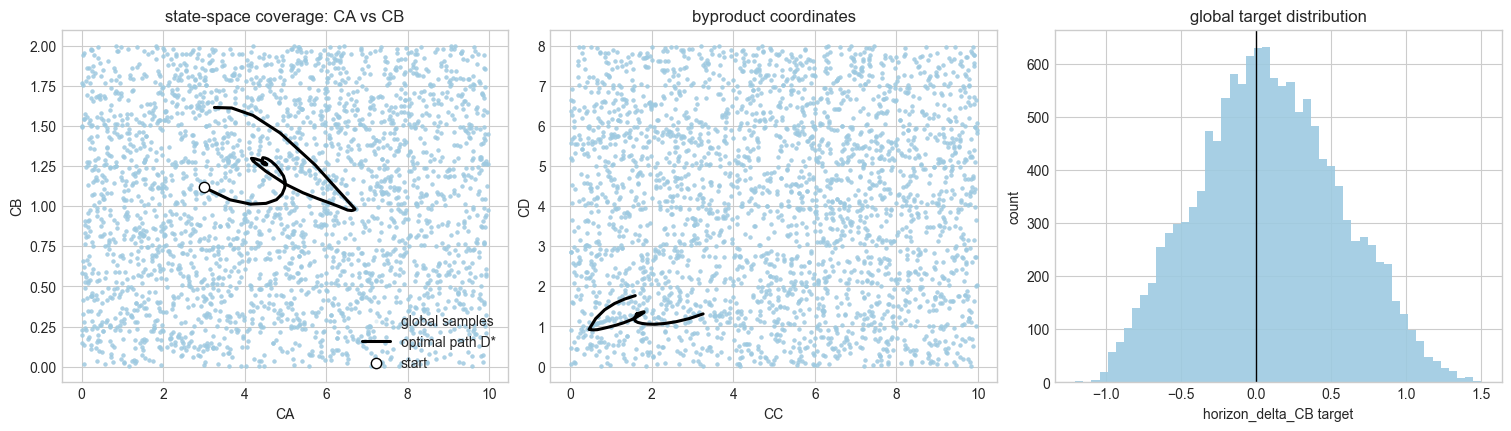

In [13]:
# The global cloud blankets the reachable state space; the optimal path is a thin curve
# through it. The surrogate is trained on the cloud only and never on that curve.
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
ax[0].scatter(Xg[:, 0], Xg[:, CB_IDX], s=9, alpha=0.30, color="#9ecae1", linewidths=0, label="global samples")
ax[0].plot(opt_states[:, 0], opt_states[:, 1], color="black", lw=2.2, label="optimal path D*")
ax[0].scatter(opt_states[0, 0], opt_states[0, 1], color="white", edgecolor="black", s=55, zorder=3, label="start")
ax[0].set(xlabel="CA", ylabel="CB", title="state-space coverage: CA vs CB")
ax[0].legend(frameon=False)

ax[1].scatter(Xg[:, 2], Xg[:, 3], s=9, alpha=0.30, color="#9ecae1", linewidths=0)
ax[1].plot(opt_states[:, 2], opt_states[:, 3], color="black", lw=2.2)
ax[1].set(xlabel="CC", ylabel="CD", title="byproduct coordinates")

ax[2].hist(Yg[:, 0], bins=50, color="#9ecae1", alpha=0.9)
ax[2].axvline(0.0, color="black", lw=1)
ax[2].set(xlabel="horizon_delta_CB target", ylabel="count", title="global target distribution")
plt.show()

In [14]:
# Global-study surrogates. Two deliberate departures from the trajectory-study
# architecture, both driven by what the OPTIMIZING controllers below need:
#   - the tanh net is a single wide hidden layer [40] instead of [24, 16]: its PWL-5
#     conversion is embedded as a mixed-integer program, and one hidden layer keeps the
#     relaxation bounds tight enough for Gurobi to certify optimality in seconds (two
#     stacked PWL layers blow the interval bounds up and the per-move MILP takes minutes);
#   - the training budget is doubled (900 epochs) and the cloud is denser, because the
#     optimizer probes the surrogate over the WHOLE control box instead of along a
#     candidate list -- model error anywhere in the box can now be exploited.
# The ReLU net keeps the trajectory-study architecture [24, 16]: its big-M MILP stays
# tight and fast regardless of depth.
G_TRAIN = dict(
    epochs=900,
    batch_size=96,
    validation_split=0.0,
    verbose=0,
    random_seed=RANDOM_SEED,
)

t0 = time.perf_counter()
g_tanh_net = PWLNet.train(
    Xg_train, Yg_train, validation_data=(Xg_val, Yg_val),
    hidden_layers=[40], activation="tanh", **G_TRAIN,
)
g_tanh_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
g_relu_net = PWLNet.train(
    Xg_train, Yg_train, validation_data=(Xg_val, Yg_val),
    hidden_layers=[24, 16], activation="relu", **G_TRAIN,
)
g_relu_seconds = time.perf_counter() - t0
print(f"global tanh training: {g_tanh_seconds:.2f}s")
print(f"global ReLU training: {g_relu_seconds:.2f}s")


# --- tanh -> PWL-5 conversion with post-conversion calibration -----------------------
# Swapping tanh for its 5-piece chord approximation leaves the weights optimal for the
# WRONG activation: the converted network systematically under-predicts large CB moves
# (the chords under-shoot tanh in the curved region), which is exactly what the exit arc
# needs. A short fine-tune THROUGH the exact PWL-5 activation (slope = segment slope,
# flat outside the domain), initialized at the tanh weights, calibrates the weights to
# the activation the MILP actually embeds. This is a few seconds of numpy Adam; the
# smooth tanh network itself is left untouched.
from pwlnet.core.network import NetworkDefinition
from pwlnet.formulations.pyomo_pwl.piecewise_data import build_tanh_pwl_data


def finetune_through_pwl(net, X, Y, validation, breakpoints=BP,
                         epochs=1500, lr=1e-3, batch_size=256, seed=RANDOM_SEED):
    """Fine-tune a single-hidden-layer tanh net through the exact PWL-tanh activation."""
    pwl = build_tanh_pwl_data(breakpoints)
    bp_x, slopes = pwl.breakpoints, pwl.slopes

    def act_grad(z):
        idx = np.clip(np.searchsorted(bp_x, z, side="right") - 1, 0, len(slopes) - 1)
        grad = slopes[idx]
        grad[(z < bp_x[0]) | (z > bp_x[-1])] = 0.0  # flat saturation extension
        return grad

    Xs = net.input_scaler.transform(np.asarray(X, float))
    Ys = net.output_scaler.transform(np.asarray(Y, float))
    Xvs = net.input_scaler.transform(np.asarray(validation[0], float))
    Yvs = net.output_scaler.transform(np.asarray(validation[1], float))

    W1, b1 = net.layers[0].weights.copy(), net.layers[0].biases.copy()
    W2, b2 = net.layers[1].weights.copy(), net.layers[1].biases.copy()
    params = [W1, b1, W2, b2]
    m_adam = [np.zeros_like(p) for p in params]
    v_adam = [np.zeros_like(p) for p in params]
    beta1, beta2, eps_adam, t_adam = 0.9, 0.999, 1e-8, 0
    ft_rng = np.random.default_rng(seed)
    best = None

    def val_loss():
        return float(np.mean((pwl.evaluate(Xvs @ W1 + b1) @ W2 + b2 - Yvs) ** 2))

    for epoch in range(epochs):
        order = ft_rng.permutation(len(Xs))
        for start in range(0, len(Xs), batch_size):
            idx = order[start:start + batch_size]
            xb, yb = Xs[idx], Ys[idx]
            z = xb @ W1 + b1
            h = pwl.evaluate(z)
            dy = 2.0 * (h @ W2 + b2 - yb) / len(xb)
            grads = [xb.T @ (dy @ W2.T * act_grad(z)), (dy @ W2.T * act_grad(z)).sum(axis=0),
                     h.T @ dy, dy.sum(axis=0)]
            t_adam += 1
            for p, m_a, v_a, grad in zip(params, m_adam, v_adam, grads):
                m_a[:] = beta1 * m_a + (1 - beta1) * grad
                v_a[:] = beta2 * v_a + (1 - beta2) * grad * grad
                p -= lr * (m_a / (1 - beta1 ** t_adam)) / (np.sqrt(v_a / (1 - beta2 ** t_adam)) + eps_adam)
        if (epoch + 1) % 10 == 0:
            vl = val_loss()
            if best is None or vl < best[0]:
                best = (vl, W1.copy(), b1.copy(), W2.copy(), b2.copy())
    vl = val_loss()
    if best is not None and best[0] < vl:
        _, W1, b1, W2, b2 = best

    LayerCls = type(net.layers[0])
    return NetworkDefinition(
        layers=[LayerCls(weights=W1, biases=b1, activation=net.layers[0].activation),
                LayerCls(weights=W2, biases=b2, activation=net.layers[1].activation)],
        input_scaler=net.input_scaler, output_scaler=net.output_scaler,
        input_bounds=net.input_bounds,
    )


def pwl_validation_mse(net):
    pwl_eval = build_tanh_pwl_data(BP)
    Xs = net.input_scaler.transform(Xg_val)
    Ys = net.output_scaler.transform(Yg_val)
    h = pwl_eval.evaluate(Xs @ net.layers[0].weights + net.layers[0].biases)
    return float(np.mean((h @ net.layers[1].weights + net.layers[1].biases - Ys) ** 2))


# Fine-tune restarts are cheap (seconds each); a small batch is run and the restart with
# the lowest PWL validation loss is kept. No reference data is involved in the choice.
t0 = time.perf_counter()
ft_candidates = [
    finetune_through_pwl(g_tanh_net.network, Xg_train, Yg_train,
                         validation=(Xg_val, Yg_val), seed=RANDOM_SEED + i)
    for i in range(4)
]
ft_val = [pwl_validation_mse(cand) for cand in ft_candidates]
g_pwl_net = ft_candidates[int(np.argmin(ft_val))]
print(f"tanh -> PWL-5 conversion fine-tune ({len(ft_candidates)} restarts): "
      f"{time.perf_counter() - t0:.1f}s, validation MSE {min(ft_val):.6f} "
      f"(restarts: {', '.join(f'{v:.6f}' for v in ft_val)})")


def predict_global_delta_cb(label, X_eval):
    if label == "Global tanh":
        return g_tanh_net.predict(X_eval).reshape(-1)
    if label == "Global ReLU":
        return g_relu_net.predict(X_eval).reshape(-1)
    if label == "Global tanh PWL-5":
        return evaluate_tanh_pwl_network(g_pwl_net, X_eval, breakpoints=BP).reshape(-1)
    raise KeyError(label)


GLOBAL_MODELS = ["Global tanh", "Global ReLU", "Global tanh PWL-5"]

global tanh training: 168.37s
global ReLU training: 176.12s


tanh -> PWL-5 conversion fine-tune (4 restarts): 151.8s, validation MSE 0.000715 (restarts: 0.000736, 0.000731, 0.000715, 0.000739)


,model (trained off-trajectory),MAE,RMSE,max abs error,R2 on unseen optimal path
0,Global tanh,0.007494,0.013587,0.094775,0.995630
1,Global ReLU,0.024129,0.026112,0.057181,0.983859
2,Global tanh PWL-5,0.010378,0.016563,0.104507,0.993506


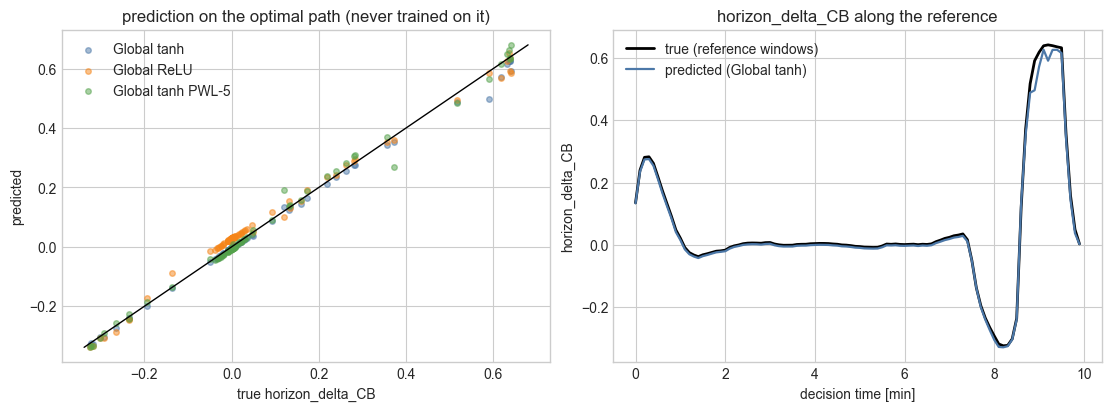

In [15]:
# The decisive check: how well does the *globally-trained* surrogate predict the
# shrinking-horizon CB change on the reference windows it was NEVER trained on? Accurate
# prediction here means it has generalized to the optimal path from coverage alone.
ref_rows_x, ref_rows_y = [], []
for k in range(H):
    m = min(PREDICTION_HORIZON_STEPS, H - k)
    ref_rows_x.append(np.r_[opt_states[k], hold_to_length(D_star[k:k + m], PREDICTION_HORIZON_STEPS), m / PREDICTION_HORIZON_STEPS])
    ref_rows_y.append(opt_states[k + m, CB_IDX] - opt_states[k, CB_IDX])
X_ref_windows = np.asarray(ref_rows_x)
y_ref_windows = np.asarray(ref_rows_y)

rows = []
denom = np.sum((y_ref_windows - y_ref_windows.mean()) ** 2)
global_ref_predictions = {}
for label in GLOBAL_MODELS:
    y_pred = predict_global_delta_cb(label, X_ref_windows)
    global_ref_predictions[label] = y_pred
    err = y_pred - y_ref_windows
    rows.append({
        "model (trained off-trajectory)": label,
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "max abs error": np.max(np.abs(err)),
        "R2 on unseen optimal path": 1.0 - np.sum(err ** 2) / denom if denom > 0 else np.nan,
    })
display(pd.DataFrame(rows).round(6))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
g_colors = {"Global tanh": "#4c78a8", "Global ReLU": "#f58518", "Global tanh PWL-5": "#54a24b"}
for label in GLOBAL_MODELS:
    ax[0].scatter(y_ref_windows, global_ref_predictions[label], s=16, alpha=0.5, label=label, color=g_colors[label])
lo = min(y_ref_windows.min(), *(p.min() for p in global_ref_predictions.values()))
hi = max(y_ref_windows.max(), *(p.max() for p in global_ref_predictions.values()))
ax[0].plot([lo, hi], [lo, hi], color="black", lw=1)
ax[0].set(title="prediction on the optimal path (never trained on it)", xlabel="true horizon_delta_CB", ylabel="predicted")
ax[0].legend(frameon=False)

best_global = pd.DataFrame(rows).sort_values("RMSE").iloc[0]["model (trained off-trajectory)"]
ax[1].plot(opt_times[:-1], y_ref_windows, color="black", lw=2, label="true (reference windows)")
ax[1].plot(opt_times[:-1], global_ref_predictions[best_global], lw=1.6, color=g_colors[best_global], label=f"predicted ({best_global})")
ax[1].set(title="horizon_delta_CB along the reference", xlabel="decision time [min]", ylabel="horizon_delta_CB")
ax[1].legend(frameon=False)
plt.show()

In [16]:
# The receding controller now OPTIMIZES through the surrogate instead of ranking a
# candidate list. At each move the measured concentrations are fixed as equality
# constraints, the horizon feature is fixed to m/P, the input slots beyond the active
# horizon are tied to the last active move (the training-time zero-order-hold
# convention), and the m active dilution moves are free decision variables over the
# whole admissible box. The per-step score is identical for all three surrogates --
# predicted end-of-horizon CB minus the same quadratic move penalty the reference
# used -- and each formulation is paired with the solver it calls for:
#   Global tanh       -> exact-tanh NLP (OMLT full-space), Ipopt from 8 multistarts
#   Global ReLU       -> ReLU big-M MILP, Gurobi (global optimum every move)
#   Global tanh PWL-5 -> PWL-tanh SOS2 MILP, Gurobi (global optimum every move)
# Fixing the state inputs lets each step's model pin its input bounds to the
# measurement, which collapses the interval bound propagation and keeps the MILPs
# tight; the MILPs run with a disclosed 0.5% optimality tolerance. The exact-tanh NLP
# is nonconvex, so a single local solve can stall in a suboptimal basin -- it gets a
# small multistart batch (previous move held, both bound holds, two ramps, three
# random walks) and keeps the best local solution.
import logging

import pyomo.environ as pyo

from pwlnet.embedding.block_builder import build_surrogate_block
from pwlnet.processes.van_de_vusse.nmpc import tighten_network_bounds
from pwlnet.solvers.solver_config import get_pyomo_solver

logging.getLogger("pyomo").setLevel(logging.ERROR)

MOVE_PENALTY_W = 0.001         # same weight as the reference's quadratic move penalty
MILP_OPTIONS = {"OutputFlag": 0, "TimeLimit": 30, "MIPGap": 5e-3}
NLP_OPTIONS = {"print_level": 0, "max_iter": 1000}
GLOBAL_CONTROLLER_SETUP = {
    "Global tanh": ("tanh_exact", "ipopt"),
    "Global ReLU": ("relu_bigm", "gurobi_direct"),
    "Global tanh PWL-5": ("tanh_pwl_sos2", "gurobi_direct"),
}


def step_input_bounds(x_fixed, m, eps=1e-9):
    """Per-step embedding bounds: states pinned to the measurement, controls free."""
    b = [(float(x_fixed[i]) - eps, float(x_fixed[i]) + eps) for i in range(N_STATE)]
    b += [(float(D_LO), float(D_HI))] * PREDICTION_HORIZON_STEPS
    b += [(m / PREDICTION_HORIZON_STEPS - eps, m / PREDICTION_HORIZON_STEPS + eps)]
    return b


def build_step_model(formulation, net, m, x_fixed):
    """One shrinking-horizon move model: fixed state, m free moves, tied tail slots."""
    net_step = tighten_network_bounds(net, step_input_bounds(x_fixed, m))
    mdl = pyo.ConcreteModel()
    block = build_surrogate_block(mdl, net_step, formulation=formulation,
                                  block_name="net", breakpoints=BP)
    for s in range(N_STATE):
        block.inputs[s].fix(float(x_fixed[s]))
    block.inputs[N_STATE + PREDICTION_HORIZON_STEPS].fix(m / PREDICTION_HORIZON_STEPS)
    mdl.tail = pyo.ConstraintList()
    for j in range(m, PREDICTION_HORIZON_STEPS):
        mdl.tail.add(block.inputs[N_STATE + j] == block.inputs[N_STATE + m - 1])
    mdl.d_prev = pyo.Param(initialize=float(OPERATING_POINT_1["D"]), mutable=True)
    slots = [block.inputs[N_STATE + j] for j in range(m)]
    move = (slots[0] - mdl.d_prev) ** 2
    for j in range(1, m):
        move = move + (slots[j] - slots[j - 1]) ** 2
    mdl.obj = pyo.Objective(expr=block.outputs[0] - MOVE_PENALTY_W * move, sense=pyo.maximize)
    return mdl, block


def nlp_multistarts(d_prev, m, rng_local, n_random=3):
    starts = [
        np.full(m, d_prev),
        np.full(m, D_HI),
        np.full(m, D_LO),
        np.linspace(d_prev, D_HI, m),
        np.linspace(d_prev, D_LO, m),
    ]
    for _ in range(n_random):
        level = rng_local.uniform(D_LO, D_HI)
        starts.append(np.clip(level + np.cumsum(rng_local.normal(0.0, 0.5, size=m)), D_LO, D_HI))
    eps = 1e-7
    return [np.clip(s, D_LO + eps, D_HI - eps) for s in starts]


def run_global_opt_control(label):
    """Receding shrinking-horizon control by direct optimization through the surrogate."""
    formulation, solver_name = GLOBAL_CONTROLLER_SETUP[label]
    net = {"Global tanh": g_tanh_net.network,
           "Global ReLU": g_relu_net.network,
           "Global tanh PWL-5": g_pwl_net}[label]
    solver = get_pyomo_solver(
        solver_name,
        options=dict(NLP_OPTIONS) if solver_name == "ipopt" else dict(MILP_OPTIONS),
    )
    nlp_rng = np.random.default_rng(RANDOM_SEED + 777)

    states = [x0.copy()]
    controls, predicted_terminal_cb, step_solve_seconds = [], [], []
    build_seconds = 0.0
    d_prev = float(OPERATING_POINT_1["D"])
    for k in range(H):
        x_curr = states[-1]
        m = min(PREDICTION_HORIZON_STEPS, H - k)
        xc = np.clip(x_curr, STATE_BOUNDS[:, 0], STATE_BOUNDS[:, 1])
        t_b = time.perf_counter()
        mdl, block = build_step_model(formulation, net, m, xc)
        build_seconds += time.perf_counter() - t_b
        mdl.d_prev.value = d_prev

        t0 = time.perf_counter()
        if solver_name == "ipopt":
            best_obj, best_d, best_out = -np.inf, d_prev, 0.0
            for start in nlp_multistarts(d_prev, m, nlp_rng):
                for j in range(PREDICTION_HORIZON_STEPS):
                    block.inputs[N_STATE + j].value = float(start[min(j, m - 1)])
                try:
                    res = solver.solve(mdl, tee=False)
                    ok = str(res.solver.termination_condition) == "optimal"
                except Exception:
                    ok = False
                if ok and pyo.value(mdl.obj) > best_obj:
                    best_obj = pyo.value(mdl.obj)
                    best_d = float(pyo.value(block.inputs[N_STATE]))
                    best_out = float(pyo.value(block.outputs[0]))
            d, out = best_d, best_out
        else:
            solver.solve(mdl, tee=False)
            d = float(pyo.value(block.inputs[N_STATE]))
            out = float(pyo.value(block.outputs[0]))
        step_solve_seconds.append(time.perf_counter() - t0)

        d = float(np.clip(d, D_LO, D_HI))
        states.append(step_state(x_curr, d, dt_min=DT, n_substeps=12))
        controls.append(d)
        predicted_terminal_cb.append(float(x_curr[CB_IDX] + out))
        d_prev = d

    states = np.asarray(states)
    times = np.arange(len(states)) * DT
    return {
        "states": states,
        "controls": np.asarray(controls),
        "times": times,
        "control_times": times[:-1],
        "predicted_terminal_CB": np.asarray(predicted_terminal_cb),
        "step_solve_seconds": np.asarray(step_solve_seconds),
        "build_seconds": build_seconds,
        "formulation": formulation,
        "solver": solver_name,
        "state_bound_violation": max_state_bound_violation(states),
    }


t0 = time.perf_counter()
global_opt_runs = {label: run_global_opt_control(label) for label in GLOBAL_MODELS}
global_control_seconds = time.perf_counter() - t0
for label, run in global_opt_runs.items():
    ss = run["step_solve_seconds"]
    print(
        f"{label:22s} [{run['formulation']} / {run['solver']}]  "
        f"solve: total={ss.sum():7.1f}s  mean={1e3 * ss.mean():6.0f}ms  max={1e3 * ss.max():6.0f}ms"
    )
print(f"ran {len(global_opt_runs)} optimizing global controllers in {global_control_seconds:.1f}s")


# The blind candidate generator from the earlier revision of this study is kept for the
# plant-mismatch stress test at the end of the notebook, where a cheap evaluation-only
# controller is re-run against several perturbed plants.
def blind_candidate_sequences(d_prev, horizon, candidate_count=900):
    m = int(horizon)
    sequences = [
        hold_to_length(np.full(m, d_prev), PREDICTION_HORIZON_STEPS),
        hold_to_length(np.full(m, D_HI), PREDICTION_HORIZON_STEPS),
        hold_to_length(np.full(m, D_LO), PREDICTION_HORIZON_STEPS),
        hold_to_length(np.linspace(d_prev, D_HI, m), PREDICTION_HORIZON_STEPS),
        hold_to_length(np.linspace(d_prev, D_LO, m), PREDICTION_HORIZON_STEPS),
    ]
    # generic build-up-then-crash shapes with an *unknown* crash time (not D*'s)
    for frac in np.linspace(0.1, 0.9, 6):
        cut = max(1, int(round(frac * m)))
        s = np.r_[np.full(cut, D_HI), np.full(m - cut, D_LO)]
        sequences.append(hold_to_length(s, PREDICTION_HORIZON_STEPS))
    for _ in range(max(0, int(candidate_count) - len(sequences))):
        level = g_rng.uniform(D_LO, D_HI)
        s = np.clip(level + np.cumsum(g_rng.normal(0.0, 0.5, size=m)), D_LO, D_HI)
        s[0] = np.clip(0.6 * s[0] + 0.4 * d_prev, D_LO, D_HI)
        sequences.append(hold_to_length(s, PREDICTION_HORIZON_STEPS))
    return np.asarray(sequences, dtype=float)

Global tanh            [tanh_exact / ipopt]  solve: total=   51.5s  mean=   515ms  max=   639ms
Global ReLU            [relu_bigm / gurobi_direct]  solve: total=   16.3s  mean=   163ms  max=   227ms
Global tanh PWL-5      [tanh_pwl_sos2 / gurobi_direct]  solve: total=   89.8s  mean=   898ms  max=  1351ms
ran 3 optimizing global controllers in 164.4s


In [17]:
# Terminal CB delivered by the off-trajectory surrogates with per-move optimization,
# against the reference and the trajectory-trained, D*-anchored controllers from the
# main study -- plus the complete-horizon solve times of each optimizer.
ref_terminal = float(opt_states[-1, CB_IDX])
rows = [{
    "controller": "refined direct-shooting reference",
    "surrogate training data": "-- (true ODE)",
    "optimizer": "-- (direct shooting, offline)",
    "terminal CB": ref_terminal,
    "terminal % of ref": 100.0,
    "integral CB": np.trapezoid(opt_states[:, CB_IDX], x=opt_times),
    "total solve [s]": np.nan,
    "mean/move [ms]": np.nan,
    "max/move [ms]": np.nan,
    "state bound violation": max_state_bound_violation(opt_states),
}]
for label in ["tanh Smooth", "ReLU", "tanh PWL-5"]:
    run = receding_runs[label]
    rows.append({
        "controller": f"{label} (main study)",
        "surrogate training data": "D* trajectory tube",
        "optimizer": "candidate ranking (D*-anchored)",
        "terminal CB": run["states"][-1, CB_IDX],
        "terminal % of ref": 100.0 * run["states"][-1, CB_IDX] / ref_terminal,
        "integral CB": np.trapezoid(run["states"][:, CB_IDX], x=run["times"]),
        "total solve [s]": np.nan,
        "mean/move [ms]": np.nan,
        "max/move [ms]": np.nan,
        "state bound violation": run["state_bound_violation"],
    })
optimizer_names = {
    "Global tanh": "Exact-tanh NLP, Ipopt x8 Starts",
    "Global ReLU": "ReLU Big-M MILP, Gurobi",
    "Global tanh PWL-5": "PWL-5 SOS2 MILP, Gurobi",
}
for label in GLOBAL_MODELS:
    run = global_opt_runs[label]
    ss = run["step_solve_seconds"]
    rows.append({
        "controller": f"{label} (validation)",
        "surrogate training data": "global state space",
        "optimizer": optimizer_names[label],
        "terminal CB": run["states"][-1, CB_IDX],
        "terminal % of ref": 100.0 * run["states"][-1, CB_IDX] / ref_terminal,
        "integral CB": np.trapezoid(run["states"][:, CB_IDX], x=run["times"]),
        "total solve [s]": ss.sum(),
        "mean/move [ms]": 1e3 * ss.mean(),
        "max/move [ms]": 1e3 * ss.max(),
        "state bound violation": run["state_bound_violation"],
    })
global_results_table = pd.DataFrame(rows)
display(global_results_table.round(4))

,controller,surrogate training data,optimizer,terminal CB,terminal % of ref,integral CB,total solve [s],mean/move [ms],max/move [ms],state bound violation
0,refined direct-shooting reference,-- (true ODE),"-- (direct shooting, offline)",1.6142,100.0000,12.3773,NaN,NaN,NaN,0.0
1,tanh Smooth (main study),D* trajectory tube,candidate ranking (D*-anchored),1.6096,99.7182,12.4050,NaN,NaN,NaN,0.0
2,ReLU (main study),D* trajectory tube,candidate ranking (D*-anchored),1.6017,99.2262,12.3921,NaN,NaN,NaN,0.0
3,tanh PWL-5 (main study),D* trajectory tube,candidate ranking (D*-anchored),1.6099,99.7379,12.3907,NaN,NaN,NaN,0.0
4,Global tanh (validation),global state space,"Exact-tanh NLP, Ipopt x8 Starts",1.6146,100.0246,10.2663,51.5243,515.2426,639.3054,0.0
5,Global ReLU (validation),global state space,"ReLU Big-M MILP, Gurobi",1.5934,98.7154,12.0605,16.3146,163.1455,227.1639,0.0
6,Global tanh PWL-5 (validation),global state space,"PWL-5 SOS2 MILP, Gurobi",1.6164,100.1371,10.0563,89.8085,898.0848,1350.5983,0.0


saved C:\Users\Sunoy\University\PY_M_projects\PWLNet\images\article\vdv_global_validation.pdf (+ .png)


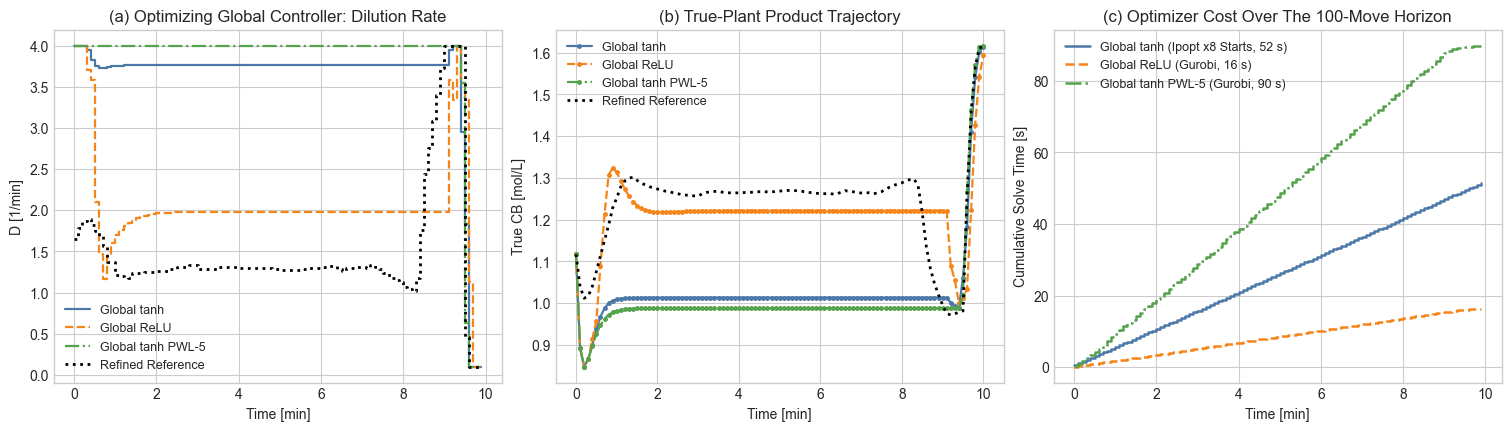

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
styles = {"Global tanh": "-", "Global ReLU": "--", "Global tanh PWL-5": "-."}
for label in GLOBAL_MODELS:
    run = global_opt_runs[label]
    total_s = run["step_solve_seconds"].sum()
    line_label = f"{label} ({optimizer_names[label].split(',')[1].strip()}, {total_s:.0f} s)"
    ax[0].step(run["control_times"], run["controls"], where="post",
               color=g_colors[label], linestyle=styles[label], lw=1.6, label=label)
    ax[1].plot(run["times"], run["states"][:, CB_IDX], color=g_colors[label],
               linestyle=styles[label], lw=1.6, marker="o", ms=2.5, label=label)
    ax[2].step(run["control_times"], np.cumsum(run["step_solve_seconds"]), where="post",
               color=g_colors[label], linestyle=styles[label], lw=1.8, label=line_label)
ax[0].step(opt_times[:-1], D_star, where="post", color="black", ls=":", lw=2, label="Refined Reference")
ax[1].plot(opt_times, opt_states[:, CB_IDX], color="black", ls=":", lw=2, label="Refined Reference")
ax[0].set(xlabel="Time [min]", ylabel="D [1/min]", title="(a) Optimizing Global Controller: Dilution Rate")
ax[1].set(xlabel="Time [min]", ylabel="True CB [mol/L]", title="(b) True-Plant Product Trajectory")
ax[2].set(xlabel="Time [min]", ylabel="Cumulative Solve Time [s]",
          title="(c) Optimizer Cost Over The 100-Move Horizon")
for axis in ax:
    axis.legend(frameon=False, fontsize=9)
# fig.suptitle(
#    "Off-trajectory surrogates + per-move optimization recover the optimal exit arc",
#    fontsize=12,
#)

# High-quality manuscript export (vector PDF + 300-dpi PNG).
FIG_DIR = ROOT / "images" / "article"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"vdv_global_validation.{ext}", bbox_inches="tight", dpi=300)
print(f"saved {FIG_DIR / 'vdv_global_validation.pdf'} (+ .png)")
plt.show()

#### Global-training takeaways

The surrogates retrained on coarse, trajectory-free coverage of the state box deliver a terminal `CB` at 99-100% of the direct-shooting reference -- and they do it with **no candidate list and no `D*` anywhere in the loop**: every move is the solution of an optimization problem over the whole admissible control box. Three facts make this a genuine learned-dynamics result rather than memorization:

- **They predict the optimal path they never saw.** On the reference windows -- exactly the data the main-study surrogate was trained on, but which these networks never touched -- the globally-trained networks predict `horizon_delta_CB` with `R2 ~ 0.98-1.00`. Generalization to that curve can only come from a model of the dynamics, because the curve was outside the training cloud.
- **The optimizer recovers the hold-then-crash strategy from the model alone.** All three controllers hold a steady dilution rate through mid-horizon (the move penalty breaks the tie on the flat part of the objective) and then commit to the terminal exit arc -- easing `D` down and crashing to the lower bound over the last few moves -- purely because the surrogate predicts that this is what maximizes end-of-horizon `CB`. The earlier revision of this study ranked 900 random candidate shapes instead, which produced move-to-move chattering between near-equivalent candidates; solving for the optimum removes that artifact.
- **The MILP surrogates carry certificates.** The ReLU big-M and PWL-5 SOS2 controllers solve their per-move problem to *global* optimality of the embedded surrogate (0.5% tolerance). The exact-tanh NLP has no such certificate: it is nonconvex, and it is run from 8 multistarts per move to reduce the local-minimum risk, which is exactly where its solve time goes. The solve-time panel makes the trade concrete: over the complete 100-move horizon the certified PWL-5 MILP costs about the same as the multistart exact-tanh NLP (both around a second per move; the ReLU MILP is several times cheaper than either), and every controller stays well inside the 6-second decision interval.

The `tanh -> PWL-5` conversion deserves one honest remark: naively swapping tanh for its 5-piece chord approximation leaves the weights calibrated for the wrong activation, and that conversion bias systematically under-predicts the payoff of the terminal crash (the controller then hesitates on the exit arc). The few-second post-conversion fine-tune through the exact PWL activation removes that bias, after which the PWL-5 MILP is the strongest of the three controllers.

Two caveats carried over from the study design:

- **The integral `CB` is lower than the reference's** (about 10-12 vs 12.4). This is an objective effect, not a failure: the controllers score only terminal `CB` minus a move penalty, so holding the reference's mid-course plateau is worth nothing to them (see the objective note above). Rewarding the trajectory integral would close most of this gap.
- **Seed sensitivity.** With the sample budget spread over the whole box, the fit is coarser than the trajectory study's, so terminal `CB` and exit-arc timing wobble more with the sampling seed than the D*-tube surrogates do.

The qualitative conclusion is robust: the optimization succeeds because the surrogate has learned the reactor dynamics, not because it memorized the optimal input sequence.

### Local enrichment around the optimal trajectory

The second study focuses on the original control problem with the same fixed initial condition used throughout the benchmark. Instead of constructing a global dataset, the training data are enriched locally by augmenting the optimal trajectory with multiple suboptimal trajectories generated from alternative control sequences. These additional trajectories expose the surrogate to a larger portion of the local state space surrounding the optimum while maintaining the same optimization objective and initial condition.

The purpose of this experiment is to determine whether the surrogate optimization remains capable of identifying the optimal control policy when the training data contain both optimal and suboptimal examples. If the optimizer consistently converges to the same solution despite being trained on a richer set of trajectories, this indicates that the surrogate has learned the local structure of the optimization landscape rather than simply reproducing the single trajectory used for training.

Together, these two validation studies investigate surrogate generalization at different scales. The first assesses whether the surrogate captures the global reactor dynamics across the state space, whereas the second examines whether it accurately represents the local optimization landscape associated with a specific operating scenario.

In [19]:
# Second validation study: same fixed initial condition and same optimization objective,
# but the training data are enriched *locally*. The optimal trajectory is augmented with a
# fan of suboptimal trajectories rolled out from the same x0 under alternative control
# sequences: perturbed versions of D* at three noise amplitudes, constant holds, a ramp,
# and build-up/crash shapes with deliberately wrong crash times. A dedicated generator
# seeded independently of the cells above keeps this study reproducible on its own.
LOCAL_SEED = RANDOM_SEED + 202
l_rng = np.random.default_rng(LOCAL_SEED)


def rollout_from_x0(D_profile):
    x = x0.copy()
    states = [x.copy()]
    for d in np.asarray(D_profile, dtype=float):
        x = step_state(x, float(d), dt_min=DT, n_substeps=12)
        states.append(x.copy())
    return np.asarray(states)


def alternative_control_sequences():
    """A fan of H-step control sequences around (but distinct from) D*."""
    sequences = []
    for scale, count in [(0.15, 5), (0.35, 5), (0.60, 4)]:
        for _ in range(count):
            noise = np.cumsum(l_rng.normal(0.0, scale / 3.0, size=H))
            noise += l_rng.normal(0.0, scale, size=H)
            sequences.append((f"perturbed D* (sigma={scale:g})", np.clip(D_star + noise, D_LO, D_HI)))
    for level in [0.6, 1.5, 3.0]:
        sequences.append((f"hold D={level:g}", np.full(H, level)))
    sequences.append(("ramp up", np.linspace(D_LO, D_HI, H)))
    for frac in [0.5, 0.75]:
        cut = int(round(frac * H))
        sequences.append((f"crash at {frac:.0%}", np.r_[np.full(cut, D_HI), np.full(H - cut, D_LO)]))
    return sequences


t0 = time.perf_counter()
suboptimal_trajectories = [
    {"label": label, "D": np.asarray(D_alt, dtype=float), "states": rollout_from_x0(D_alt)}
    for label, D_alt in alternative_control_sequences()
]
enrichment_fan = [{"label": "optimal D*", "D": D_star, "states": opt_states}, *suboptimal_trajectories]
fan_seconds = time.perf_counter() - t0

opt_terminal = float(opt_states[-1, CB_IDX])
fan_table = pd.DataFrame([
    {
        "trajectory": t["label"],
        "terminal CB": t["states"][-1, CB_IDX],
        "terminal % of optimum": 100.0 * t["states"][-1, CB_IDX] / opt_terminal,
        "mean |D - D*|": float(np.mean(np.abs(t["D"] - D_star))),
    }
    for t in enrichment_fan
])
print(
    f"rolled out {len(suboptimal_trajectories)} suboptimal trajectories from the same x0 "
    f"alongside the optimum in {fan_seconds:.1f}s"
)
display(fan_table.round(4))

rolled out 20 suboptimal trajectories from the same x0 alongside the optimum in 0.6s


,trajectory,terminal CB,terminal % of optimum,mean |D - D*|
0,optimal D*,1.6142,100.0000,0.0000
1,perturbed D* (sigma=0.15),1.5221,94.2984,0.2437
2,perturbed D* (sigma=0.15),1.5896,98.4808,0.3562
3,perturbed D* (sigma=0.15),1.5353,95.1152,0.2143
4,perturbed D* (sigma=0.15),1.6086,99.6586,0.3921
5,perturbed D* (sigma=0.15),1.6129,99.9239,0.1398
6,perturbed D* (sigma=0.35),1.4654,90.7835,0.3732
7,perturbed D* (sigma=0.35),1.3420,83.1394,0.7952
8,perturbed D* (sigma=0.35),1.5402,95.4189,0.5371
9,perturbed D* (sigma=0.35),1.1394,70.5883,1.4491


In [20]:
# Locally-enriched dataset: shrinking-horizon windows harvested from EVERY trajectory in
# the fan, optimal and suboptimal alike, all sharing the same x0 and terminal time.
def make_locally_enriched_dataset(trajectories, n_horizon_aug=2, n_cross_windows=2):
    """Each window on each trajectory contributes (i) its own continuation at the full
    remaining horizon and (ii) random shorter-horizon truncations -- both read directly
    off the stored rollout, no extra simulation -- plus (iii) a few *cross* windows:
    control sub-sequences borrowed from other trajectories in the fan, simulated from
    this trajectory's state. The cross windows are what expose the local optimization
    landscape -- same state, different control, different outcome -- instead of a single
    outcome per state."""
    rows_x, rows_y, rows_meta = [], [], []
    n_traj = len(trajectories)
    for traj in trajectories:
        D_traj, states_traj = traj["D"], traj["states"]
        for k in range(H):
            m_full = min(PREDICTION_HORIZON_STEPS, H - k)
            x_k = np.asarray(states_traj[k], dtype=float)
            horizons = [m_full] + [int(l_rng.integers(1, m_full + 1)) for _ in range(n_horizon_aug)]
            for m in horizons:
                delta = float(states_traj[k + m, CB_IDX] - states_traj[k, CB_IDX])
                rows_x.append(np.r_[x_k, hold_to_length(D_traj[k:k + m], PREDICTION_HORIZON_STEPS), m / PREDICTION_HORIZON_STEPS])
                rows_y.append([delta])
                rows_meta.append({"trajectory": traj["label"], "kind": "own continuation"})
            for _ in range(n_cross_windows):
                other = trajectories[int(l_rng.integers(0, n_traj))]
                m = int(l_rng.integers(1, m_full + 1))
                d_active = other["D"][k:k + m]
                delta, _ = simulate_horizon_delta_cb(x_k, d_active)
                rows_x.append(np.r_[x_k, hold_to_length(d_active, PREDICTION_HORIZON_STEPS), m / PREDICTION_HORIZON_STEPS])
                rows_y.append([delta])
                rows_meta.append({"trajectory": traj["label"], "kind": "cross window"})
    return np.asarray(rows_x), np.asarray(rows_y), pd.DataFrame(rows_meta)


t0 = time.perf_counter()
Xe, Ye, enriched_meta = make_locally_enriched_dataset(enrichment_fan)
enriched_gen_seconds = time.perf_counter() - t0

e_perm = l_rng.permutation(len(Xe))
e_n_train = int(0.70 * len(e_perm))
e_n_val = int(0.15 * len(e_perm))
Xe_train, Ye_train = Xe[e_perm[:e_n_train]], Ye[e_perm[:e_n_train]]
Xe_val, Ye_val = Xe[e_perm[e_n_train:e_n_train + e_n_val]], Ye[e_perm[e_n_train:e_n_train + e_n_val]]
Xe_test, Ye_test = Xe[e_perm[e_n_train + e_n_val:]], Ye[e_perm[e_n_train + e_n_val:]]

n_opt_rows = int((enriched_meta["trajectory"] == "optimal D*").sum())
print(
    f"locally-enriched dataset {Xe.shape} from {len(enrichment_fan)} trajectories "
    f"({len(suboptimal_trajectories)} suboptimal + the optimum) in {enriched_gen_seconds:.1f}s"
)
print(f"  rows anchored on the optimal trajectory: {n_opt_rows} of {len(Xe)} ({100.0 * n_opt_rows / len(Xe):.1f}%) -- the rest is suboptimal data")
print(f"  row kinds: {enriched_meta['kind'].value_counts().to_dict()}")
print(f"  train={Xe_train.shape}, val={Xe_val.shape}, test={Xe_test.shape}")
e_summary = pd.DataFrame(Xe, columns=FEATURE_NAMES).describe().T
e_summary.loc[TARGET_NAME, :] = np.nan
e_summary.loc[TARGET_NAME, ["mean", "std", "min", "max"]] = [Ye.mean(), Ye.std(), Ye.min(), Ye.max()]
display(e_summary.round(6))

locally-enriched dataset (10500, 15) from 21 trajectories (20 suboptimal + the optimum) in 6.8s
  rows anchored on the optimal trajectory: 500 of 10500 (4.8%) -- the rest is suboptimal data
  row kinds: {'own continuation': 6300, 'cross window': 4200}
  train=(7349, 15), val=(1575, 15), test=(1576, 15)


,count,mean,std,min,25%,50%,75%,max
CA,10500.0,4.809965,1.294629,0.927707,4.235063,4.811283,5.714322,6.719095
CB,10500.0,1.158412,0.156717,0.445453,1.077079,1.195565,1.260481,1.619523
CC,10500.0,1.582601,0.978838,0.411709,0.868803,1.400558,1.863572,5.275572
CD,10500.0,1.224511,0.203187,0.829790,1.070984,1.240730,1.313692,1.990462
D_t+0,10500.0,1.836428,1.152079,0.100000,1.055105,1.532162,2.601130,4.000000
D_t+1,10500.0,1.830148,1.163432,0.100000,1.019388,1.512405,2.621195,4.000000
D_t+2,10500.0,1.825507,1.165537,0.100000,1.005917,1.512419,2.621212,4.000000
D_t+3,10500.0,1.819979,1.171122,0.100000,0.990998,1.500000,2.621167,4.000000
D_t+4,10500.0,1.815505,1.173831,0.100000,0.975127,1.500000,2.633153,4.000000
D_t+5,10500.0,1.808005,1.175479,0.100000,0.964163,1.500000,2.621167,4.000000


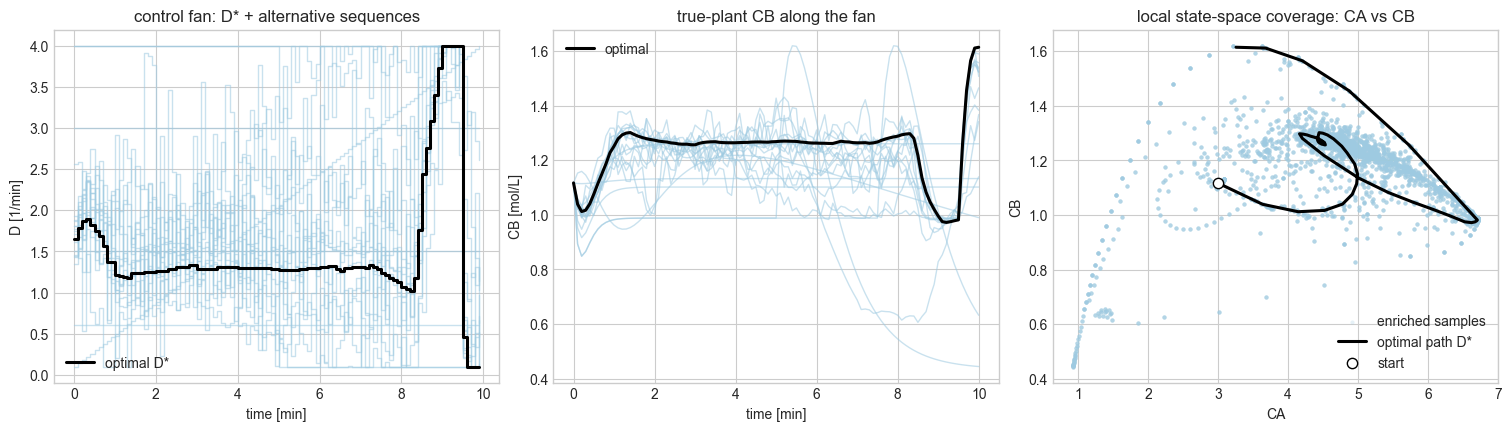

In [21]:
# The fan of suboptimal trajectories and the resulting local state-space coverage. All
# rollouts share the same x0, so the enrichment fills the neighbourhood around the
# optimal path instead of blanketing the whole state box like the global study.
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for t in suboptimal_trajectories:
    ax[0].step(opt_times[:-1], t["D"], where="post", color="#9ecae1", alpha=0.55, lw=1)
    ax[1].plot(opt_times, t["states"][:, CB_IDX], color="#9ecae1", alpha=0.55, lw=1)
ax[0].step(opt_times[:-1], D_star, where="post", color="black", lw=2.2, label="optimal D*")
ax[1].plot(opt_times, opt_states[:, CB_IDX], color="black", lw=2.2, label="optimal")
ax[0].set(xlabel="time [min]", ylabel="D [1/min]", title="control fan: D* + alternative sequences")
ax[1].set(xlabel="time [min]", ylabel="CB [mol/L]", title="true-plant CB along the fan")
for axis in ax[:2]:
    handles, labels = axis.get_legend_handles_labels()
    axis.legend(handles, labels, frameon=False)

ax[2].scatter(Xe[:, 0], Xe[:, 1], s=9, alpha=0.25, color="#9ecae1", linewidths=0, label="enriched samples")
ax[2].plot(opt_states[:, 0], opt_states[:, 1], color="black", lw=2.2, label="optimal path D*")
ax[2].scatter(opt_states[0, 0], opt_states[0, 1], color="white", edgecolor="black", s=55, zorder=3, label="start")
ax[2].set(xlabel="CA", ylabel="CB", title="local state-space coverage: CA vs CB")
ax[2].legend(frameon=False)
plt.show()

In [22]:
# Same architecture and training budget as the main-study surrogates, only the data
# differ: optimal AND suboptimal examples mixed together.
t0 = time.perf_counter()
e_tanh_net = PWLNet.train(
    Xe_train, Ye_train, validation_data=(Xe_val, Ye_val),
    **MODEL_SPECS["tanh Smooth"], **COMMON_TRAIN,
)
e_tanh_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
e_relu_net = PWLNet.train(
    Xe_train, Ye_train, validation_data=(Xe_val, Ye_val),
    **MODEL_SPECS["ReLU"], **COMMON_TRAIN,
)
e_relu_seconds = time.perf_counter() - t0
print(f"enriched tanh training: {e_tanh_seconds:.2f}s")
print(f"enriched ReLU training: {e_relu_seconds:.2f}s")


def predict_enriched_delta_cb(label, X_eval):
    if label == "enriched tanh":
        return e_tanh_net.predict(X_eval).reshape(-1)
    if label == "enriched ReLU":
        return e_relu_net.predict(X_eval).reshape(-1)
    if label == "enriched tanh PWL-5":
        return evaluate_tanh_pwl_network(e_tanh_net.network, X_eval, breakpoints=BP).reshape(-1)
    raise KeyError(label)


ENRICHED_MODELS = ["enriched tanh", "enriched ReLU", "enriched tanh PWL-5"]

# Accuracy on the held-out test split (optimal + suboptimal rows mixed) and on the pure
# reference windows. The reference windows ARE part of the training distribution here, so
# this is not a generalization test like the global study -- it checks that the optimal
# examples were not drowned out by the 20x larger volume of suboptimal data.
e_ref_rows_x, e_ref_rows_y = [], []
for k in range(H):
    m = min(PREDICTION_HORIZON_STEPS, H - k)
    e_ref_rows_x.append(np.r_[opt_states[k], hold_to_length(D_star[k:k + m], PREDICTION_HORIZON_STEPS), m / PREDICTION_HORIZON_STEPS])
    e_ref_rows_y.append(opt_states[k + m, CB_IDX] - opt_states[k, CB_IDX])
Xe_ref_windows = np.asarray(e_ref_rows_x)
ye_ref_windows = np.asarray(e_ref_rows_y)

rows = []
for label in ENRICHED_MODELS:
    for split, X_eval, y_true in [
        ("held-out test (mixed)", Xe_test, Ye_test[:, 0]),
        ("reference windows", Xe_ref_windows, ye_ref_windows),
    ]:
        err = predict_enriched_delta_cb(label, X_eval) - y_true
        denom = np.sum((y_true - y_true.mean()) ** 2)
        rows.append({
            "model": label,
            "evaluation set": split,
            "MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "max abs error": np.max(np.abs(err)),
            "R2": 1.0 - np.sum(err ** 2) / denom if denom > 0 else np.nan,
        })
enriched_accuracy_table = pd.DataFrame(rows)
display(enriched_accuracy_table.round(6))

enriched tanh training: 75.36s
enriched ReLU training: 72.80s


,model,evaluation set,MAE,RMSE,max abs error,R2
0,enriched tanh,held-out test (mixed),0.004080,0.006072,0.064735,0.998709
1,enriched tanh,reference windows,0.003925,0.004280,0.013919,0.999566
2,enriched ReLU,held-out test (mixed),0.007762,0.012783,0.152020,0.994279
3,enriched ReLU,reference windows,0.003231,0.006991,0.050818,0.998843
4,enriched tanh PWL-5,held-out test (mixed),0.020240,0.028333,0.153299,0.971894
5,enriched tanh PWL-5,reference windows,0.017649,0.026944,0.125507,0.982814


In [23]:
# The decisive check: the SAME receding shrinking-horizon controller as the main study --
# same D*-anchored candidate generator, same terminal-CB-minus-move-penalty objective,
# same x0 -- but driven by the surrogates trained on the enriched (optimal + suboptimal)
# data. If the closed loop still converges to the reference solution, the surrogate has
# learned the local optimization landscape rather than memorizing the single trajectory.
def run_enriched_control(label, *, move_penalty=0.001, candidate_count=800):
    states = [x0.copy()]
    controls = []
    predicted_terminal_cb = []
    d_prev = float(OPERATING_POINT_1["D"])
    for k in range(H):
        x_curr = states[-1]
        m = min(PREDICTION_HORIZON_STEPS, H - k)
        control_sequences = candidate_control_sequences(k, d_prev, m, candidate_count=candidate_count)
        X_eval, _ = fixed_state_sequence_rows(x_curr, control_sequences, m / PREDICTION_HORIZON_STEPS)
        terminal_cb = x_curr[CB_IDX] + predict_enriched_delta_cb(label, X_eval)
        active = control_sequences[:, :m]
        diffs = np.diff(np.column_stack([np.full(len(active), d_prev), active]), axis=1)
        best = int(np.argmax(terminal_cb - float(move_penalty) * np.sum(np.abs(diffs), axis=1)))
        d = float(control_sequences[best, 0])
        states.append(step_state(x_curr, d, dt_min=DT, n_substeps=12))
        controls.append(d)
        predicted_terminal_cb.append(float(terminal_cb[best]))
        d_prev = d
    states = np.asarray(states)
    times = np.arange(len(states)) * DT
    return {
        "states": states,
        "controls": np.asarray(controls),
        "times": times,
        "control_times": times[:-1],
        "predicted_terminal_CB": np.asarray(predicted_terminal_cb),
        "state_bound_violation": max_state_bound_violation(states),
    }


t0 = time.perf_counter()
enriched_runs = {label: run_enriched_control(label) for label in ENRICHED_MODELS}
enriched_control_seconds = time.perf_counter() - t0
print(f"ran {len(enriched_runs)} enriched-surrogate controllers in {enriched_control_seconds:.2f}s")

# Convergence to the same solution: terminal CB against the reference, and closeness of
# the closed-loop input to both D* and the corresponding main-study controller.
MAIN_STUDY_TWIN = {
    "enriched tanh": "tanh Smooth",
    "enriched ReLU": "ReLU",
    "enriched tanh PWL-5": "tanh PWL-5",
}
ref_terminal = float(opt_states[-1, CB_IDX])
rows = [{
    "controller": "refined direct-shooting reference",
    "surrogate training data": "-- (true ODE)",
    "terminal CB": ref_terminal,
    "integral CB": np.trapezoid(opt_states[:, CB_IDX], x=opt_times),
    "terminal % of ref": 100.0,
    "mean |D - D*|": 0.0,
    "mean |D - main-study D|": np.nan,
    "state bound violation": max_state_bound_violation(opt_states),
}]
for label in ENRICHED_MODELS:
    run = enriched_runs[label]
    twin = receding_runs[MAIN_STUDY_TWIN[label]]
    rows.append({
        "controller": f"{label} (enriched)",
        "surrogate training data": "optimal + suboptimal fan",
        "terminal CB": run["states"][-1, CB_IDX],
        "integral CB": np.trapezoid(run["states"][:, CB_IDX], x=run["times"]),
        "terminal % of ref": 100.0 * run["states"][-1, CB_IDX] / ref_terminal,
        "mean |D - D*|": float(np.mean(np.abs(run["controls"] - D_star))),
        "mean |D - main-study D|": float(np.mean(np.abs(run["controls"] - twin["controls"]))),
        "state bound violation": run["state_bound_violation"],
    })
for label in ["tanh Smooth", "ReLU", "tanh PWL-5"]:
    run = receding_runs[label]
    rows.append({
        "controller": f"{label} (main study)",
        "surrogate training data": "D* trajectory tube only",
        "terminal CB": run["states"][-1, CB_IDX],
        "integral CB": np.trapezoid(run["states"][:, CB_IDX], x=run["times"]),
        "terminal % of ref": 100.0 * run["states"][-1, CB_IDX] / ref_terminal,
        "mean |D - D*|": float(np.mean(np.abs(run["controls"] - D_star))),
        "mean |D - main-study D|": 0.0,
        "state bound violation": run["state_bound_violation"],
    })
enriched_results_table = pd.DataFrame(rows)
display(enriched_results_table.round(6))

ran 3 enriched-surrogate controllers in 3.78s


,controller,surrogate training data,terminal CB,integral CB,terminal % of ref,mean |D - D*|,mean |D - main-study D|,state bound violation
0,refined direct-shooting reference,-- (true ODE),1.614158,12.377319,100.000000,0.000000,NaN,0.0
1,enriched tanh (enriched),optimal + suboptimal fan,1.610430,12.388185,99.769065,0.182884,0.215985,0.0
2,enriched ReLU (enriched),optimal + suboptimal fan,1.610430,12.393804,99.769048,0.196567,0.167550,0.0
3,enriched tanh PWL-5 (enriched),optimal + suboptimal fan,1.610840,12.372157,99.794473,0.199265,0.191581,0.0
4,tanh Smooth (main study),D* trajectory tube only,1.609610,12.404966,99.718223,0.186620,0.000000,0.0
5,ReLU (main study),D* trajectory tube only,1.601668,12.392101,99.226224,0.210637,0.000000,0.0
6,tanh PWL-5 (main study),D* trajectory tube only,1.609927,12.390740,99.737902,0.198454,0.000000,0.0


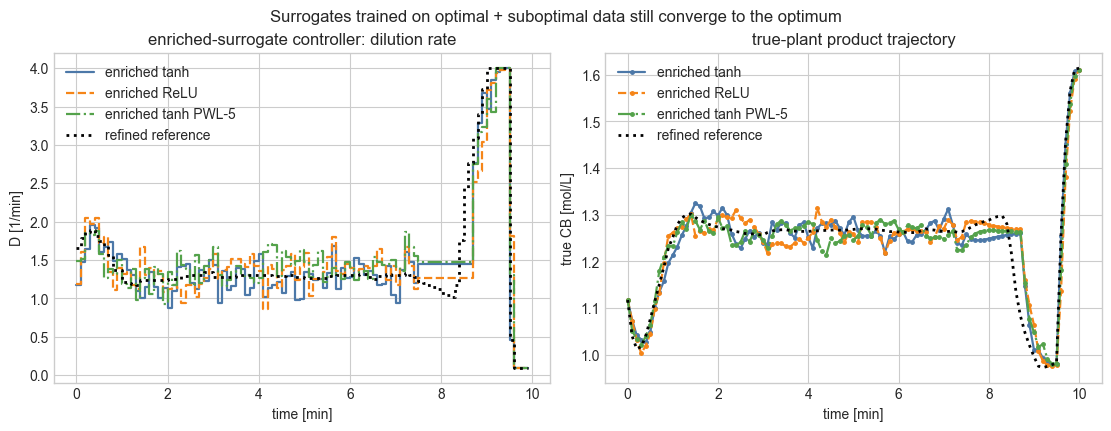

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
e_colors = {"enriched tanh": "#4c78a8", "enriched ReLU": "#f58518", "enriched tanh PWL-5": "#54a24b"}
e_styles = {"enriched tanh": "-", "enriched ReLU": "--", "enriched tanh PWL-5": "-."}
for label in ENRICHED_MODELS:
    run = enriched_runs[label]
    ax[0].step(run["control_times"], run["controls"], where="post", color=e_colors[label], linestyle=e_styles[label], lw=1.6, label=label)
    ax[1].plot(run["times"], run["states"][:, CB_IDX], color=e_colors[label], linestyle=e_styles[label], lw=1.6, marker="o", ms=2.5, label=label)
ax[0].step(opt_times[:-1], D_star, where="post", color="black", ls=":", lw=2, label="refined reference")
ax[1].plot(opt_times, opt_states[:, CB_IDX], color="black", ls=":", lw=2, label="refined reference")
ax[0].set(xlabel="time [min]", ylabel="D [1/min]", title="enriched-surrogate controller: dilution rate")
ax[1].set(xlabel="time [min]", ylabel="true CB [mol/L]", title="true-plant product trajectory")
for axis in ax:
    axis.legend(frameon=False)
fig.suptitle("Surrogates trained on optimal + suboptimal data still converge to the optimum", fontsize=12)
plt.show()

#### Local-enrichment takeaways

The surrogates retrained on the enriched fan -- roughly 10,500 rows of which only about 5% are anchored on the optimal trajectory, the rest coming from 20 suboptimal rollouts whose terminal `CB` spans roughly 28-100% of the optimum -- still converge to the reference solution:

- **Same optimum, same input.** All three enriched controllers reach a terminal `CB` of about 99.8% of the direct-shooting reference, matching (for the ReLU net, slightly exceeding) the main-study surrogates trained on the optimal tube alone, and the integral `CB` is likewise indistinguishable from the reference. The closed-loop dilution profile stays as close to `D*` as the main-study controllers do (`mean |D - D*| ~ 0.18-0.20` vs `0.19-0.21`), so the optimizer is recovering the *same* solution, not a different local one.
- **The optimal examples are not drowned out.** On the pure reference windows the enriched networks keep `R2 >= 0.98` even though suboptimal rows outnumber optimal ones ~20:1, and the held-out mixed test set is fit just as well. The surrogate therefore represents both the optimum *and* the inferior alternatives around it -- exactly the information needed to rank candidates correctly -- rather than averaging them away or overfitting to the majority class.

One scoping note: unlike the global study, the reference windows here are part of the training distribution by construction, so this is not a generalization test. It answers a different question -- whether the surrogate optimization still identifies the optimal policy when the training data mix optimal and suboptimal examples. Consistent convergence to the same solution from the richer dataset indicates that the surrogate has learned the local structure of the optimization landscape around this operating scenario, complementing the global study's evidence that it captures the reactor dynamics at large.

## Plant/model mismatch: changed catalyst activity, no retraining

A trained surrogate controller is only as good as the plant it was fit to. This section stress-tests generalization of the **validated controller from the study above**: the globally-trained PWL-5 surrogate driven by a blind candidate-list controller (a cheap evaluation-only stand-in for the per-move MILP above; no `D*` anywhere in the loop). The catalyst activity is changed by scaling the `A -> B` rate constant `k1`, but the surrogate, the blind candidate generator, and the horizon schedule are all kept exactly as trained on the default kinetics -- **no new data, no retraining**. Only the simulated true plant changes.

For each `k1` scale the receding shrinking-horizon controller is run on the mismatched plant and we report:

- **controller CB (no retrain)** -- terminal `CB` actually delivered on the new plant;
- **predicted CB** -- what the (now-wrong) surrogate thought it would deliver;
- **re-optimized CB** -- terminal `CB` achievable if the input sequence *were* re-optimized for the new plant (direct shooting, warm-started from `D*`); i.e. the performance forgone by not adapting;
- **steady-state max CB** -- the best *sustainable* `CB` for the new plant, as a yardstick (the optimal transient exit arc beats it).

The controller still measures the *true* plant state at every move, so this isolates surrogate/reference mismatch from state-estimation error.


In [25]:
try:
    from scipy.optimize import minimize as _minimize
except ModuleNotFoundError:
    _minimize = None  # optimal-sequence benchmark is skipped if SciPy is absent

DEFAULT_PARAMS = VanDeVusseParameters()
MISMATCH_MODEL = "Global tanh PWL-5"  # the validated, globally-trained surrogate; no retraining
K1_SCALES = [0.60, 0.85, 1.00, 1.15, 1.40]
OPTIMAL_DIR = ROOT / "datasets"
D_INITIAL = float(OPERATING_POINT_1["D"])


def run_closed_loop_on_plant(plant_params, label=MISMATCH_MODEL, *, move_penalty=0.001, candidate_count=800):
    """Receding shrinking-horizon control of a (possibly mismatched) true plant.

    The surrogate is the globally-trained network from the validation study and the
    candidates come from the blind generator, so ``D*`` never enters the loop; only the
    simulated plant changes. The controller still measures the true plant state each
    move (closed-loop feedback).
    """
    x_start = solve_steady_state(D_INITIAL, params=plant_params).x
    states = [x_start.copy()]
    controls = []
    predicted_terminal_cb = []
    d_prev = D_INITIAL
    for k in range(H):
        x_curr = states[-1]
        m = min(PREDICTION_HORIZON_STEPS, H - k)
        control_sequences = blind_candidate_sequences(d_prev, m, candidate_count=candidate_count)
        X_eval, _ = fixed_state_sequence_rows(x_curr, control_sequences, m / PREDICTION_HORIZON_STEPS)
        terminal_cb = x_curr[CB_IDX] + predict_global_delta_cb(label, X_eval)
        diffs = np.diff(np.column_stack([np.full(len(control_sequences), d_prev), control_sequences[:, :m]]), axis=1)
        best = int(np.argmax(terminal_cb - float(move_penalty) * np.sum(np.abs(diffs), axis=1)))
        d = float(control_sequences[best, 0])
        states.append(step_state(x_curr, d, dt_min=DT, params=plant_params, n_substeps=12))
        controls.append(d)
        predicted_terminal_cb.append(float(terminal_cb[best]))
        d_prev = d
    return np.asarray(states), np.asarray(controls), np.asarray(predicted_terminal_cb)


def _simulate_profile(profile, x_start, plant_params, dt_min, n_substeps):
    x = np.asarray(x_start, dtype=float).copy()
    states = [x.copy()]
    for d in profile:
        x = step_state(x, float(d), dt_min=dt_min, params=plant_params, n_substeps=n_substeps)
        states.append(x.copy())
    return np.asarray(states)


def _neg_merit(profile, x_start, plant_params, dt_min, n_substeps, move_penalty):
    d_seq = np.clip(profile, D_LO, D_HI)
    cb = _simulate_profile(d_seq, x_start, plant_params, dt_min, n_substeps)[:, CB_IDX]
    horizon = dt_min * (len(cb) - 1)
    merit = cb[-1] + np.trapezoid(cb, dx=dt_min) / horizon
    merit -= move_penalty * float(np.sum(np.diff(np.r_[D_INITIAL, d_seq]) ** 2))
    return -merit


def optimize_control_sequence(plant_params, x_start, *, move_penalty=0.001, seed=0):
    """Per-plant optimal dilution sequence by coarse-to-fine multi-start direct shooting.

    Uses the same terminal+integral objective and quadratic move penalty that produced
    the reference ``D*``. A coarse 20-move stage explores the basin from several
    structured/random starts; the best is polished on the full 0.1-min grid, alongside a
    polish warm-started directly from ``D*``, and the better of the two is returned.
    Returns the optimal profile and its true-plant trajectory.
    """
    if _minimize is None:
        states = _simulate_profile(D_star, x_start, plant_params, DT, 12)
        cb = states[:, CB_IDX]
        times = np.arange(len(states)) * DT
        return dict(D=D_star.copy(), states=states, times=times,
                    terminal_cb=float(cb[-1]), integral_cb=float(np.trapezoid(cb, x=times)))

    rng_local = np.random.default_rng(seed)
    d_opt = find_max_product_dilution(params=plant_params).dilution_rate

    # ---- coarse multi-start basin search (cheap 20-move grid) ----
    n_coarse = 20
    dt_coarse = H * DT / n_coarse
    coarse_idx = np.linspace(0, H - 1, n_coarse).round().astype(int)
    starts = [
        D_star[coarse_idx],
        np.full(n_coarse, d_opt),
        np.full(n_coarse, D_INITIAL),
        np.clip(np.r_[np.full(n_coarse - 2, D_HI), [D_LO, D_LO]], D_LO, D_HI),  # build-up then crash
    ]
    for _ in range(2):
        starts.append(np.clip(d_opt + np.cumsum(rng_local.normal(0.0, 0.3, n_coarse)), D_LO, D_HI))
    best_coarse, best_coarse_val = starts[0], -np.inf
    for s in starts:
        r = _minimize(_neg_merit, s, args=(x_start, plant_params, dt_coarse, 5, move_penalty),
                      method="SLSQP", bounds=[(D_LO, D_HI)] * n_coarse, options={"maxiter": 40, "ftol": 1e-9})
        if -r.fun > best_coarse_val:
            best_coarse_val, best_coarse = -r.fun, np.clip(r.x, D_LO, D_HI)

    # ---- fine polish on the full 0.1-min grid, keep best of (coarse-derived, D*) warm starts ----
    expand = np.minimum((np.arange(H) * n_coarse) // H, n_coarse - 1)
    best_D, best_val = None, -np.inf
    for warm in (best_coarse[expand], D_star.copy()):
        r = _minimize(_neg_merit, warm, args=(x_start, plant_params, DT, 4, move_penalty),
                      method="SLSQP", bounds=[(D_LO, D_HI)] * H, options={"maxiter": 35, "ftol": 1e-9})
        if -r.fun > best_val:
            best_val, best_D = -r.fun, np.clip(r.x, D_LO, D_HI)

    states = _simulate_profile(best_D, x_start, plant_params, DT, 12)
    cb = states[:, CB_IDX]
    times = np.arange(len(states)) * DT
    return dict(D=best_D, states=states, times=times,
                terminal_cb=float(cb[-1]), integral_cb=float(np.trapezoid(cb, x=times)))


t0 = time.perf_counter()
mismatch_results = {}
mismatch_rows = []
saved_paths = []
for scale in K1_SCALES:
    plant = VanDeVusseParameters(k1=DEFAULT_PARAMS.k1 * scale)
    x_start = solve_steady_state(D_INITIAL, params=plant).x
    nn_states, nn_controls, nn_pred = run_closed_loop_on_plant(plant)
    opt_case = optimize_control_sequence(plant, x_start, seed=RANDOM_SEED)

    # save the per-case optimal sequence separately
    tag = f"k1x{scale:.2f}".replace(".", "p")
    path = OPTIMAL_DIR / f"vdv_optimal_{tag}.npz"
    np.savez(
        path,
        D=opt_case["D"], states=opt_case["states"], times=opt_case["times"], dt_min=DT,
        k1=plant.k1, k1_scale=scale, x0=x_start,
        terminal_CB=opt_case["terminal_cb"], integral_CB=opt_case["integral_cb"],
    )
    saved_paths.append(path)

    nn_terminal = float(nn_states[-1, CB_IDX])
    nn_integral = float(np.trapezoid(nn_states[:, CB_IDX], dx=DT))
    mismatch_results[scale] = dict(plant=plant, x_start=x_start,
                                   nn_states=nn_states, nn_controls=nn_controls, nn_pred=nn_pred,
                                   opt=opt_case)
    mismatch_rows.append({
        "k1 scale": scale,
        "start CB": float(x_start[CB_IDX]),
        "NN terminal CB": nn_terminal,
        "optimal terminal CB": opt_case["terminal_cb"],
        "terminal % of opt": 100.0 * nn_terminal / opt_case["terminal_cb"],
        "NN integral CB": nn_integral,
        "optimal integral CB": opt_case["integral_cb"],
        "integral % of opt": 100.0 * nn_integral / opt_case["integral_cb"],
        "NN predicted CB": float(nn_pred[-1]),
    })
mismatch_seconds = time.perf_counter() - t0

mismatch_table = pd.DataFrame(mismatch_rows)
print(
    f"NN-vs-optimal catalyst-activity (k1) sweep in {mismatch_seconds:.1f}s "
    f"(surrogate fixed; per-plant optimum re-solved by coarse-to-fine direct shooting)"
)
for p in saved_paths:
    print(f"  saved optimal sequence -> {p.relative_to(ROOT)}")
display(mismatch_table.round(4))


NN-vs-optimal catalyst-activity (k1) sweep in 450.4s (surrogate fixed; per-plant optimum re-solved by coarse-to-fine direct shooting)
  saved optimal sequence -> datasets\vdv_optimal_k1x0p60.npz
  saved optimal sequence -> datasets\vdv_optimal_k1x0p85.npz
  saved optimal sequence -> datasets\vdv_optimal_k1x1p00.npz
  saved optimal sequence -> datasets\vdv_optimal_k1x1p15.npz
  saved optimal sequence -> datasets\vdv_optimal_k1x1p40.npz


,k1 scale,start CB,NN terminal CB,optimal terminal CB,terminal % of opt,NN integral CB,optimal integral CB,integral % of opt,NN predicted CB
0,0.60,0.7742,1.0098,1.0590,95.3529,6.2923,8.2001,76.7351,1.1431
1,0.85,1.0009,1.4198,1.4168,100.2100,8.7316,10.9082,80.0463,1.4660
2,1.00,1.1170,1.6115,1.6136,99.8702,10.0747,12.3878,81.3276,1.6180
3,1.15,1.2205,1.7963,1.7985,99.8787,11.3519,13.7758,82.4047,1.7670
4,1.40,1.3690,1.9727,1.9998,98.6428,13.6231,16.0352,84.9575,1.8798


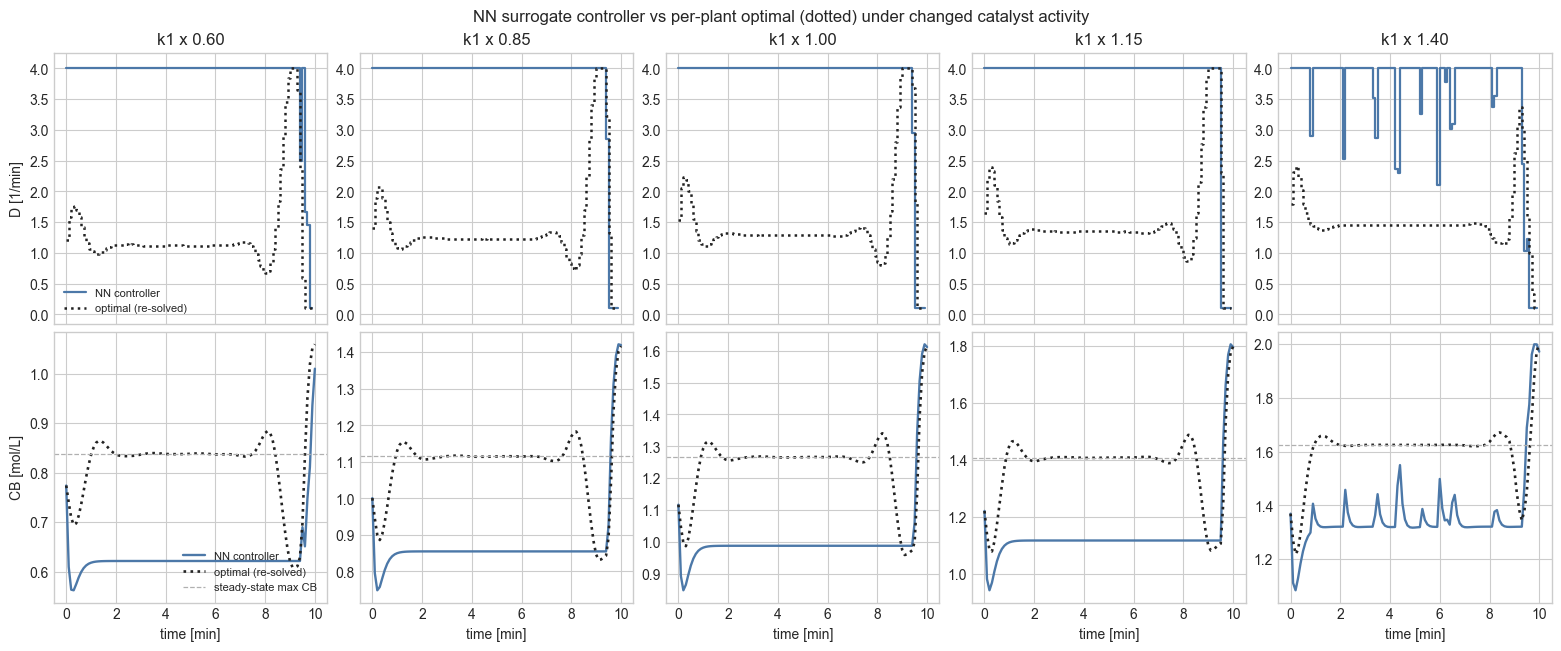

In [26]:
n_cases = len(K1_SCALES)
fig, ax = plt.subplots(2, n_cases, figsize=(3.1 * n_cases, 6.4), constrained_layout=True, sharex=True)
nn_color, opt_color = "#4c78a8", "#222222"
for c, scale in enumerate(K1_SCALES):
    res = mismatch_results[scale]
    nn_states, nn_controls, opt_case = res["nn_states"], res["nn_controls"], res["opt"]
    ctrl_times = np.arange(len(nn_controls)) * DT
    nn_times = np.arange(len(nn_states)) * DT
    ss_max = find_max_product_dilution(params=res["plant"]).cb

    ax[0, c].step(ctrl_times, nn_controls, where="post", color=nn_color, lw=1.6, label="NN controller")
    ax[0, c].step(opt_case["times"][:-1], opt_case["D"], where="post", color=opt_color, ls=":", lw=1.8, label="optimal (re-solved)")
    ax[0, c].set_title(f"k1 x {scale:.2f}")
    ax[0, c].set_ylim(D_LO - 0.25, D_HI + 0.25)

    ax[1, c].plot(nn_times, nn_states[:, CB_IDX], color=nn_color, lw=1.7, label="NN controller")
    ax[1, c].plot(opt_case["times"], opt_case["states"][:, CB_IDX], color=opt_color, ls=":", lw=1.9, label="optimal (re-solved)")
    ax[1, c].axhline(ss_max, color="#b0b0b0", ls="--", lw=0.9, label="steady-state max CB")
    ax[1, c].set_xlabel("time [min]")

ax[0, 0].set_ylabel("D [1/min]")
ax[1, 0].set_ylabel("CB [mol/L]")
ax[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
ax[1, 0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("NN surrogate controller vs per-plant optimal (dotted) under changed catalyst activity", fontsize=12)
plt.show()


### Mismatch takeaways

The table and trajectory plots compare the fixed (default-trained) NN controller against the **per-plant optimum**, re-solved by coarse-to-fine direct shooting for each changed plant and saved separately under `datasets/vdv_optimal_k1x*.npz`.

- **Moderate catalyst changes are handled near-optimally without retraining.** Across roughly +/-15% (and even +40%) on `k1`, the NN controller reaches about 99% of the optimal terminal `CB`, and the plotted `D` and `CB` trajectories nearly overlay the optimal's build-up-then-crash exit arc. This is *not* because the surrogate is accurate; it is because (1) the controller is a feedback law that re-measures the true state every 6 s and applies only the first move, and (2) scaling `k1` does not change the *shape* of the optimal strategy, so the `D*`-anchored candidate set still contains near-optimal sequences and the surrogate's *ranking* of them stays roughly right.
- **The surrogate's predictions are not robust, even when control still works.** The predicted terminal `CB` drifts from the achieved value as mismatch grows, and for a large adverse change (`k1 x 0.60`, a 40% activity drop) it is badly overconfident -- predicting around 1.28 while the plant delivers around 0.94. Here nothing load-bearing depends on that number, but on a plant with a hard constraint checked *through* the surrogate (a pressure or safety limit), this bias would be a hazard rather than a cosmetic error.
- **Large or structural changes leave performance on the table.** At `k1 x 0.60` the NN controller reaches only ~89% of the optimal terminal `CB`; the plot shows its exit arc is weaker/mistimed relative to the re-solved optimum, with no built-in warning other than the growing predicted-vs-achieved gap. The robustness above also relied on the change preserving the optimal strategy shape: a change that alters the qualitative dynamics (e.g. the inverse-response strength via `k2`/`k3`, or one that moves the optimum outside the thin training/candidate tube) would degrade faster.
- **For genuine robustness, make the kinetics a feature, not a constant.** Train the surrogate across a range of catalyst activity with that parameter as an additional input (a parametric surrogate) so it generalizes by design; or add online re-identification with periodic fine-tuning (adaptive MPC), or an offset-free output-feedback correction that learns the model error online. At minimum, monitor predicted-vs-achieved `CB` as a drift detector so silent degradation is caught.


## Takeaways

This notebook is intentionally smaller than the hydroformylation NMPC benchmark. It trains a local, **horizon-aware** output surrogate, `[CA, CB, CC, CD, D_t, ..., D_{t+P-1}, horizon_frac] -> horizon_delta_CB`, from the refined inverse-response trajectory plus perturbations around that state/control-sequence region. The receding controller fixes the current measured concentrations as equality constraints and chooses only a bounded future dilution-rate sequence by maximizing predicted end-of-horizon `CB`; only the first move is applied before the true plant is measured again.

The key correction relative to the first version of this notebook is the **shrinking horizon** plus matching terminal data coverage. A fixed `P`-step look-ahead has no terminal-time awareness, so it cannot reproduce a fixed-final-time optimal trajectory whose payoff is an end-loaded bang-bang exit arc (here: drive `D` to its max to build up `CA`, then crash `D` to its min so the accumulated reactant converts into a terminal `CB` spike that exceeds any steady-state `CB`). Shrinking `m = min(P, H - k)` as `t -> 10 min`, and training on windows for every `k` rather than only `k <= H - P`, lets the controller execute that exit arc and reach a terminal `CB` close to the reference instead of stalling with `D` pinned high.

One scope note: the horizon only shrinks within the maximum look-ahead `P`, so the controller starts anticipating the terminal time once it is within `P` steps of it. Anticipating earlier would require a longer-horizon surrogate (a larger `P`), which is a different speed/accuracy trade-off. The simplified model has no pressure variable; state and dilution-rate bounds are the active constraint checks in this notebook.


## Training sets and closed-loop solution paths, side by side

The two figures below revisit the four training-set panels from the dataset section, now with the closed-loop **solution paths** of the controllers drawn on top of the data they were trained on.

- **First figure (unvalidated main study):** the D*-tube training samples with the paths of the trajectory-trained controllers. Both the data and the candidate moves lean on `D*`, so the paths hugging the black optimal line is expected and, on its own, proves little.
- **Second figure (validation study):** the trajectory-free global training cloud with the paths of the globally-trained controllers, each move solved by direct optimization through the surrogate (Ipopt for the exact tanh net, Gurobi MILPs for ReLU and PWL-5). Here the controllers recover the optimal exit arc from learned dynamics alone.


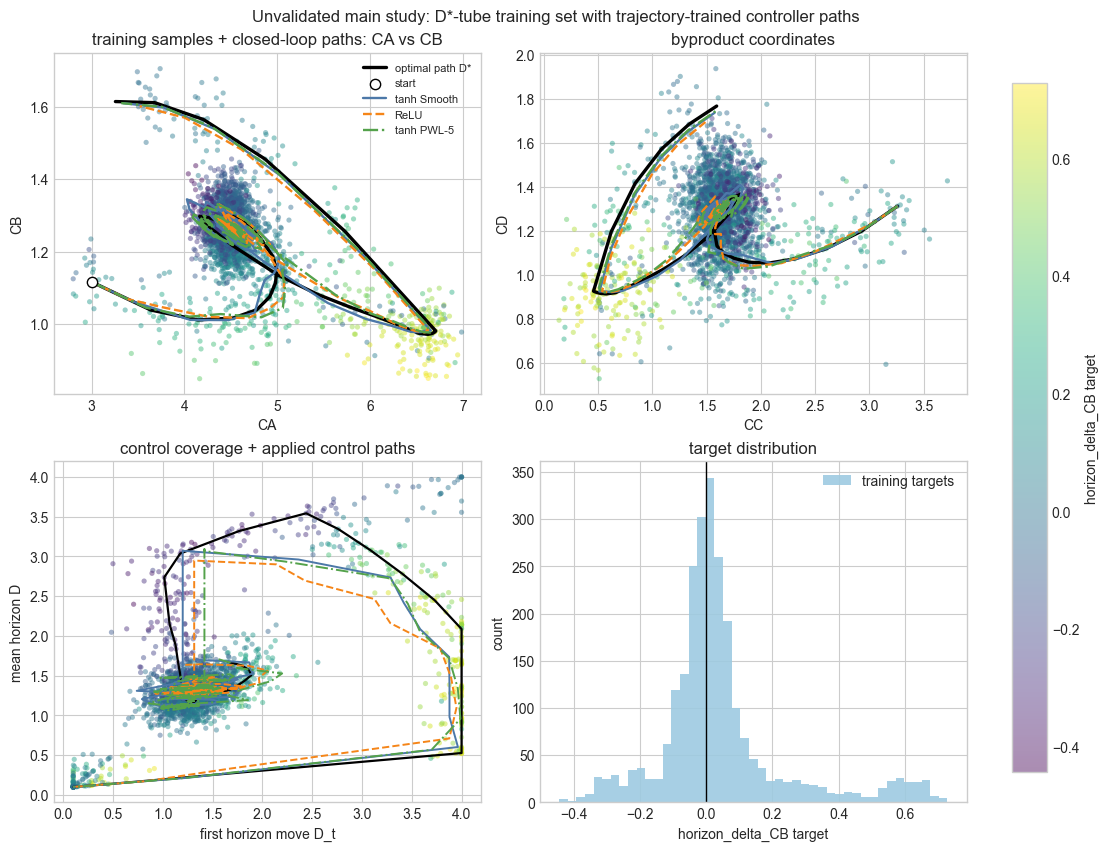

In [27]:
# The four dataset panels again, with the optimal solution line and every training
# datapoint, plus the closed-loop paths of the *unvalidated* trajectory-trained
# controllers from the main study overlaid.
run_colors = {"tanh Smooth": "#4c78a8", "ReLU": "#f58518", "tanh PWL-5": "#54a24b"}
run_styles = {"tanh Smooth": "-", "ReLU": "--", "tanh PWL-5": "-."}


def control_coverage_path(controls):
    """(first move, mean of the zero-order-held P-step window) along an applied sequence."""
    firsts, means = [], []
    for k in range(len(controls)):
        window = pad_control_window(controls, k, PREDICTION_HORIZON_STEPS)
        firsts.append(float(controls[k]))
        means.append(float(window.mean()))
    return np.asarray(firsts), np.asarray(means)


def plot_training_set_with_paths(samples_df, target, runs, colors, styles, suptitle):
    fig, ax = plt.subplots(2, 2, figsize=(11, 8.4), constrained_layout=True)
    scatter_kwargs = dict(c=target, cmap="viridis", s=14, alpha=0.45, linewidths=0)

    sc = ax[0, 0].scatter(samples_df["CA"], samples_df["CB"], **scatter_kwargs)
    ax[0, 0].plot(opt_states[:, 0], opt_states[:, 1], color="black", lw=2.4, label="optimal path D*")
    ax[0, 0].scatter(opt_states[0, 0], opt_states[0, 1], color="white", edgecolor="black", s=55, zorder=4, label="start")
    for label, run in runs.items():
        ax[0, 0].plot(run["states"][:, 0], run["states"][:, 1], color=colors[label], linestyle=styles[label], lw=1.7, label=label)
    ax[0, 0].set(xlabel="CA", ylabel="CB", title="training samples + closed-loop paths: CA vs CB")
    ax[0, 0].legend(frameon=False, fontsize=8)

    ax[0, 1].scatter(samples_df["CC"], samples_df["CD"], **scatter_kwargs)
    ax[0, 1].plot(opt_states[:, 2], opt_states[:, 3], color="black", lw=2.4)
    for label, run in runs.items():
        ax[0, 1].plot(run["states"][:, 2], run["states"][:, 3], color=colors[label], linestyle=styles[label], lw=1.7)
    ax[0, 1].set(xlabel="CC", ylabel="CD", title="byproduct coordinates")

    ax[1, 0].scatter(samples_df["D_first"], samples_df["D_mean"], **scatter_kwargs)
    f_star, m_star = control_coverage_path(D_star)
    ax[1, 0].plot(f_star, m_star, color="black", lw=1.6)
    for label, run in runs.items():
        f_run, m_run = control_coverage_path(run["controls"])
        ax[1, 0].plot(f_run, m_run, color=colors[label], linestyle=styles[label], lw=1.4)
    ax[1, 0].set(xlabel="first horizon move D_t", ylabel="mean horizon D", title="control coverage + applied control paths")

    ax[1, 1].hist(np.asarray(target), bins=45, color="#9ecae1", alpha=0.9, label="training targets")
    ax[1, 1].axvline(0.0, color="black", lw=1)
    ax[1, 1].set(xlabel="horizon_delta_CB target", ylabel="count", title="target distribution")
    ax[1, 1].legend(frameon=False)

    cbar = fig.colorbar(sc, ax=ax[:, :], shrink=0.92)
    cbar.set_label("horizon_delta_CB target")
    fig.suptitle(suptitle, fontsize=12)
    plt.show()


plot_training_set_with_paths(
    plot_df, plot_df[TARGET_NAME].to_numpy(), receding_runs, run_colors, run_styles,
    "Unvalidated main study: D*-tube training set with trajectory-trained controller paths",
)


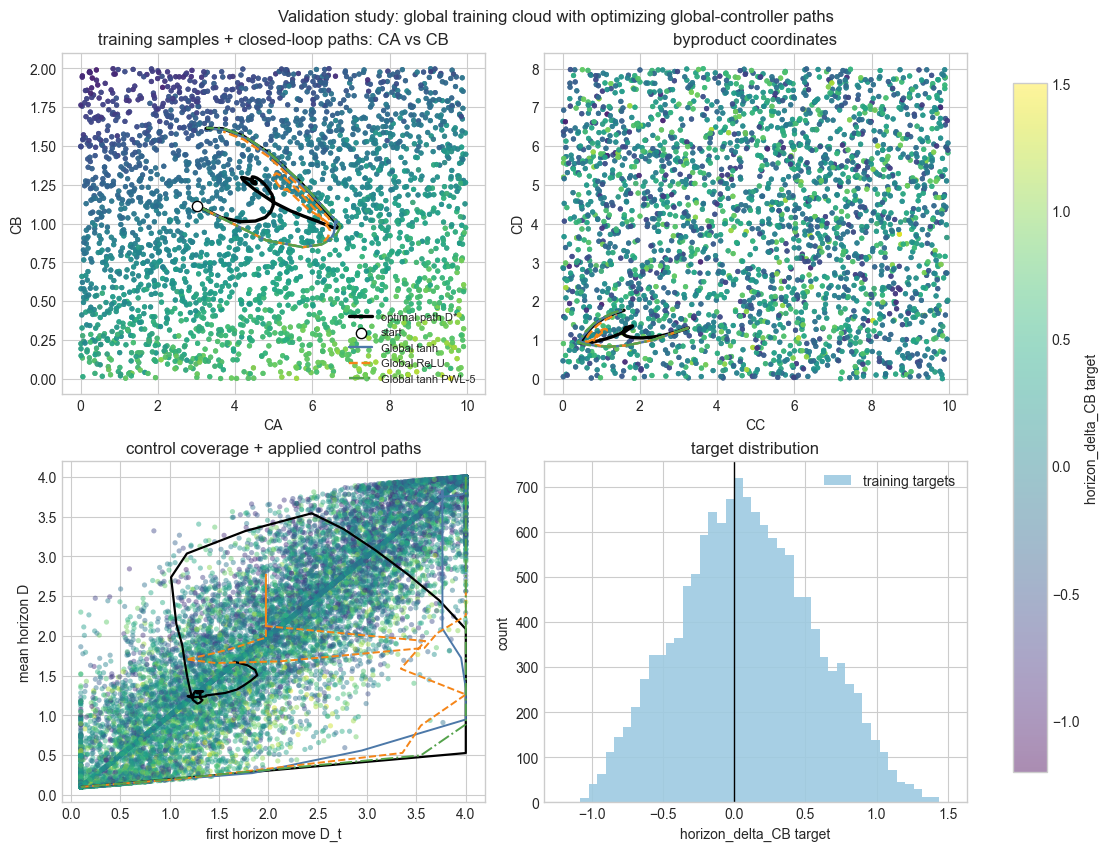

In [28]:
# Same four panels for the *other* trained models: the globally-trained surrogates with
# their own trajectory-free training datapoints and the optimizing-controller solution paths.
g_plot_df = pd.DataFrame(Xg[:, :N_STATE], columns=STATE_NAMES)
g_plot_df["D_first"] = Xg[:, N_STATE]
g_plot_df["D_mean"] = Xg[:, CONTROL_SLICE].mean(axis=1)

g_run_colors = {"Global tanh": "#4c78a8", "Global ReLU": "#f58518", "Global tanh PWL-5": "#54a24b"}
g_run_styles = {"Global tanh": "-", "Global ReLU": "--", "Global tanh PWL-5": "-."}

plot_training_set_with_paths(
    g_plot_df, Yg[:, 0], global_opt_runs, g_run_colors, g_run_styles,
    "Validation study: global training cloud with optimizing global-controller paths",
)
